# Assignment 1. Pruning for CNN

> ### 이 노트북 읽는 법
> 이 파일은 `1. Pruning for CNN_answer.ipynb`에 **파이썬 초보자용 해설**을 덧붙인 버전입니다.
> - 원본의 셀(설명·코드·실행 결과)은 **그대로** 두었습니다.
> - 번호가 붙은 코드 셀(`# 1` ~ `# 33`) **바로 아래**마다 `📘 셀 N 해설` 칸을 추가했습니다.
> - 해설은 **한 줄 요약 → 코드 뜯어보기 → 출력/그래프 해석** 순서로 되어 있습니다. 코드와 실행 결과를 먼저 훑어본 뒤 해설을 읽으면 이해하기 쉽습니다.
>
> **미리 알아 둘 용어**
> - **가중치(weight, 파라미터)** : 모델이 학습으로 얻은 숫자들. 모델의 "지식"에 해당합니다.
> - **프루닝(Pruning, 가지치기)** : 덜 중요한 가중치를 0으로 만들어 모델을 가볍게 하는 기법
> - **Sparsity(희소도)** : 전체 가중치 중 0으로 만든 비율. 0.8이면 80%를 지웠다는 뜻
> - **마스크(mask)** : 가중치와 같은 모양의 0/1 표. 1은 "유지", 0은 "제거"
> - **텐서(Tensor)** : PyTorch에서 쓰는 다차원 숫자 배열

## Goals

본 실습은 CNN 모델의 다양한 Pruning 기법을 이해하고, 이를 구현하여 각 방법이 모델의 정확도와 효율성에 어떤 영향을 주는지 확인하는 것을 목표로 합니다.


## Contents

1. **Pruning Granularity:**
    - Fine-grained, Vector-level, Kernel-level, Channel-level의 차이를 학습하고 구현합니다.
2. **Pruning Ratio:**
    - 제거할 가중치의 비율(Sparsity)을 결정하는 방법을 배웁니다. Layer-wise와 Global 방식의 차이를 실습을 통해 확인합니다.
3. **Pruning Schedule:**
    - One-shot Pruning 및 Iterative Pruning을 이해하고, Linear 및 Cubic Scheduling 방법을 적용하여 성능 변화를 분석합니다.

# Setup

다음 단계에 따라 실습 환경을 준비합니다.

- **필수 모듈 가져오기**: 실습을 위한 필요한 라이브러리들을 import 합니다.
- **Seed 설정**: 결과 재현성을 위해 난수 생성 Seed를 설정합니다.
- **CIFAR-10 데이터셋 준비**: CIFAR-10 데이터셋을 다운로드하고 DataLoader를 생성합니다.
- **사전 학습된 모델 로딩**: 미리 학습된 CNN 모델(VGG 기반)을 로드합니다.

In [1]:
# 1
import math
import random
from typing import List

import numpy as np
import torch
from datasets import load_dataset
from matplotlib import pyplot as plt
from torch import nn
from torch.optim import Optimizer
from torch.optim.lr_scheduler import LambdaLR
from torch.utils.data import DataLoader, Dataset
from torchvision.datasets import CIFAR10
from torchvision.transforms import Compose, RandomCrop, RandomHorizontalFlip, ToTensor
from tqdm.auto import tqdm

### 📘 셀 1 해설
**한 줄 요약:** 실습에 필요한 "도구 상자(라이브러리)"들을 불러오는 셀입니다. 아직 아무 계산도 하지 않습니다.

**파이썬 문법 먼저**
- `import math` : `math`라는 도구 상자 전체를 가져옵니다. 쓸 때는 `math.ceil(...)`처럼 앞에 이름을 붙입니다.
- `import numpy as np` : `numpy`를 가져오되 **`np`라는 별명**으로 부르겠다는 뜻입니다.
- `from torch import nn` : `torch` 상자 안에서 **`nn`만 꺼내옵니다.** 이후 `torch.nn` 대신 `nn`이라고 짧게 쓸 수 있습니다.

**각 라이브러리의 역할**

| 코드 | 역할 |
|---|---|
| `math`, `random` | 파이썬 기본 수학 함수 / 난수(무작위 수) 생성 |
| `typing.List` | "이 함수는 리스트를 돌려준다" 같은 **타입 힌트**를 적을 때 사용 (실행에는 영향 없음) |
| `numpy` (`np`) | 숫자 배열 계산 라이브러리 |
| `torch` | 딥러닝 프레임워크 PyTorch. **텐서(Tensor)** = GPU에서도 계산할 수 있는 다차원 숫자 배열 |
| `datasets.load_dataset` | Hugging Face에서 데이터셋을 내려받는 함수 |
| `matplotlib.pyplot` (`plt`) | 그래프 그리기 |
| `torch.nn` (`nn`) | 신경망 부품(Conv2d, Linear, 손실 함수 등) 모음 |
| `Optimizer`, `LambdaLR` | 학습 도구의 **타입 이름** (타입 힌트용) |
| `DataLoader`, `Dataset` | 데이터를 묶음(batch) 단위로 꺼내 주는 도구 / 데이터셋의 기본 틀 |
| `torchvision ... Compose, RandomCrop, RandomHorizontalFlip, ToTensor` | 이미지 전처리·증강 도구 |
| `tqdm` | 반복문의 **진행률 막대**를 보여 주는 도구 |

> 참고: `CIFAR10`은 import만 하고 실제로는 쓰지 않습니다(셀 3에서 Hugging Face 버전을 대신 사용).

In [25]:
# 2
# Seed 설정
random.seed(0)
np.random.seed(0)
torch.manual_seed(0)

### 📘 셀 2 해설
**한 줄 요약:** 난수의 "출발점(seed)"을 0으로 고정해서, **몇 번을 실행해도 같은 결과**가 나오게 합니다.

- 컴퓨터의 "무작위"는 사실 seed라는 숫자에서 출발해 계산으로 만들어 내는 값입니다. seed가 같으면 뽑히는 난수 순서도 같습니다.
- 난수를 만드는 곳이 3군데(파이썬 기본 `random`, `numpy`, `torch`)라서 **세 곳 모두** 고정합니다.
- 고정하지 않으면 데이터 섞는 순서, 이미지 증강 결과 등이 실행할 때마다 달라져서 실험 비교가 어려워집니다.

**출력 해석:** `<torch._C.Generator at 0x...>`는 마지막 줄 `torch.manual_seed(0)`이 돌려준 값(난수 생성기 객체)이 화면에 찍힌 것일 뿐, 의미 있는 결과는 아닙니다. 주피터는 셀의 **마지막 줄 값**을 자동으로 출력합니다.

## CIFAR-10 데이터셋 준비

CIFAR-10 데이터셋을 다운로드하고 DataLoader를 설정합니다. CIFAR-10은 32x32 크기의 RGB 이미지로 구성된 데이터셋으로, 비행기, 자동차, 새 등 10개의 클래스에 대해 각각 6,000개씩 총 60,000개의 이미지를 포함하고 있습니다. 이 중 50,000개는 학습용(train), 10,000개는 테스트용(test)으로 분리되어 있습니다. 데이터 증강(Data Augmentation)을 위해 학습 데이터에는 RandomCrop과 RandomHorizontalFlip을 적용하고, DataLoader를 통해 배치 단위로 효율적인 학습이 가능하도록 구성합니다.

In [26]:
# 3
image_size = 32
transforms = {
    "train": Compose([
        RandomCrop(image_size, padding=4),
        RandomHorizontalFlip(),
        ToTensor(),
    ]),
    "test": Compose([
        ToTensor(),
    ]),
}

# torchvision의 공식 다운로드 서버 에러를 피하기 위해
# Hugging Face Hub에서 CIFAR-10을 로드하는 커스텀 Dataset 클래스
class HFCIFAR10(Dataset):
    def __init__(self, split, transform=None):
        self.data = load_dataset("uoft-cs/cifar10", split=split)
        self.transform = transform
        self.targets = list(self.data["label"])

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        # Subset에서 numpy.int64가 들어올 수 있으므로 Python int로 변환
        idx = int(idx)
        item = self.data[idx]
        # Hugging Face CIFAR-10 field names: img, label
        image = item["img"].convert("RGB")
        label = item["label"]
        if self.transform is not None:
            image = self.transform(image)
        return image, label

dataset = {split: HFCIFAR10(split=split, transform=transforms[split])
           for split in ["train", "test"]}

dataloader = {
    split: DataLoader(dataset[split], batch_size=512,
                      shuffle=(split=='train'),
                      num_workers=0, pin_memory=True)
    for split in ['train', 'test']
}

### 📘 셀 3 해설
**한 줄 요약:** CIFAR-10 이미지 데이터를 내려받고, 모델에 **512장씩 묶어서** 넣어 줄 `dataloader`를 만듭니다.

**① 전처리 규칙 `transforms`** — `{"train": ..., "test": ...}` 형태의 **딕셔너리**(이름표 → 값)입니다.
- `Compose([...])` : 여러 전처리를 **순서대로** 적용하는 묶음
- `RandomCrop(32, padding=4)` : 이미지 테두리에 4픽셀씩 여백을 붙인 뒤 32×32 크기로 **무작위 위치**를 잘라냄 → 이미지가 살짝 이동한 효과
- `RandomHorizontalFlip()` : 50% 확률로 **좌우 반전**
- `ToTensor()` : 사진(PIL 이미지)을 0~1 사이 숫자로 된 텐서로 변환
- 학습용에만 무작위 변형(**데이터 증강**)을 넣고, 테스트용은 공정한 평가를 위해 `ToTensor()`만 적용합니다.

**② `class HFCIFAR10(Dataset)`** — "나만의 데이터셋" 설계도입니다. PyTorch의 `Dataset`을 물려받아(상속) 아래 3가지를 정의합니다.
- `__init__` : 객체를 만들 때 **한 번** 실행. 데이터를 내려받아 `self.data`에 저장합니다. `self`는 "나 자신(이 객체)"을 가리킵니다.
- `__len__` : `len(dataset)`을 했을 때 돌려줄 값 = 데이터 개수
- `__getitem__` : `dataset[5]`처럼 **번호로 꺼낼 때** 실행. `idx`번째 이미지를 RGB로 바꾸고 전처리를 적용한 뒤 `(이미지, 정답)` 쌍을 돌려줍니다.

**③ 딕셔너리 컴프리헨션** — 아래 두 코드는 같은 뜻입니다.
```python
dataset = {split: HFCIFAR10(split=split, transform=transforms[split]) for split in ["train", "test"]}

# 풀어서 쓰면
dataset = {}
for split in ["train", "test"]:
    dataset[split] = HFCIFAR10(split=split, transform=transforms[split])
```

**④ `DataLoader` 옵션**
- `batch_size=512` : 한 번에 512장씩 꺼냄
- `shuffle=(split=='train')` : 학습용일 때만 `True` → 학습 데이터만 순서를 섞음
- `num_workers=0` : 데이터 읽기에 보조 프로세스를 쓰지 않음(윈도우에서 오류를 피하는 안전한 설정)
- `pin_memory=True` : GPU로 데이터를 더 빨리 옮기기 위한 옵션

> 결과: 학습 50,000장 → 98묶음, 테스트 10,000장 → 20묶음. 뒤에 나오는 진행률 막대의 `98`, `20`이 바로 이 숫자입니다.

## 모델 로딩

사전 학습된 CNN 모델을 불러옵니다. 이 모델은 Pruning 기법을 적용하기 전 기준 모델로 사용됩니다. 본 실습에서는 VGG 구조의 모델을 사용하며, CIFAR-10 데이터셋으로 미리 학습된 가중치를 활용합니다. 모델의 연산 효율을 높이기 위해 GPU에서 실행되도록 설정합니다.

In [27]:
# 4
TORCH_HUB_REPO = "SKKU-ESLAB/pytorch-models"
MODEL_NAME = "cifar10_vgg9_bn"

model = torch.hub.load(TORCH_HUB_REPO, MODEL_NAME, pretrained=True)
if torch.cuda.is_available():
    model = model.cuda()

print(model)

VGG(
  (backbone): Sequential(
    (conv0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn0): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu0): ReLU(inplace=True)
    (conv1): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu1): ReLU(inplace=True)
    (pool0): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (conv2): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn2): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu2): ReLU(inplace=True)
    (conv3): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu3): ReLU(inplace=True)
    (pool1): MaxPo

Using cache found in C:\Users\bioyo/.cache\torch\hub\SKKU-ESLAB_pytorch-models_main


### 📘 셀 4 해설
**한 줄 요약:** 이미 CIFAR-10으로 학습을 마친 **VGG9 모델**을 인터넷에서 내려받아 GPU에 올립니다.

- `torch.hub.load(저장소, 모델이름, pretrained=True)` : GitHub 저장소 `SKKU-ESLAB/pytorch-models`에서 모델 구조와 **학습이 끝난 가중치**(`pretrained=True`)를 가져옵니다.
- `torch.cuda.is_available()` : GPU를 쓸 수 있으면 `True`. 그 경우 `model.cuda()`로 모델을 GPU 메모리로 옮깁니다.
- `print(model)` : 모델의 구조를 글자로 출력합니다.

**출력 읽는 법**
- `Conv2d(64, 128, kernel_size=(3, 3), ...)` : 입력 채널 64개 → 출력 채널 128개, 3×3 필터를 쓰는 **합성곱 층**
- `BatchNorm2d` : 값의 분포를 안정시키는 층 / `ReLU` : 음수를 0으로 만드는 활성화 함수 / `MaxPool2d` : 이미지 크기를 절반으로 줄이는 층
- `backbone`(특징 추출부)에 conv0~conv7 **8개**, 마지막 `classifier`(분류기, Linear) **1개** → 가중치 층이 총 9개라서 VGG**9**입니다.

> 이후 실습에서 "프루닝 대상"은 이 **9개 층의 weight**입니다.

## 모델 크기 평가

모델의 총 파라미터 개수를 계산하여 모델의 크기를 평가합니다. 각 파라미터의 element 수를 더하여 총 개수를 구하고, 이를 통해 모델의 크기를 비트 단위로 변환합니다. 데이터 너비는 일반적으로 32비트(float)를 사용합니다. 이를 통해 모델이 차지하는 메모리 용량을 확인하고 프루닝의 필요성을 강조할 수 있으며, 프루닝 후 크기가 얼마나 감소했는지 정량적으로 평가할 수 있습니다.

In [28]:
# 5
def get_num_parameters(model: nn.Module, count_nonzero_only=False) -> int:
    """
    모델의 총 파라미터 수 계산
    """
    num_counted_elements = 0
    for param in model.parameters():
        num_counted_elements += param.count_nonzero() if count_nonzero_only else param.numel()
    return num_counted_elements

def get_model_size(model: nn.Module, data_width=32, count_nonzero_only=False) -> int:
    """
    모델의 크기를 비트 단위로 계산
    """
    return get_num_parameters(model, count_nonzero_only) * data_width

dense_model_size = get_model_size(model)
print(f"dense model has size={dense_model_size/ (1024 ** 2) / 8:.2f} MiB")

dense model has size=35.20 MiB


### 📘 셀 5 해설
**한 줄 요약:** 모델의 **파라미터(가중치) 개수**와 **용량(MiB)**을 계산하는 함수 2개를 만들고, 원본 모델의 크기를 출력합니다.

**`get_num_parameters`**
- `model.parameters()` : 모델 안의 모든 가중치 텐서를 하나씩 꺼내 줍니다.
- `param.numel()` : 텐서 안의 숫자 개수 (**num**ber of **el**ements). 예) 모양이 (128, 64, 3, 3)이면 128×64×3×3 = 73,728개
- `param.count_nonzero()` : 0이 **아닌** 숫자의 개수
- `A if 조건 else B` : 조건이 참이면 A, 거짓이면 B를 쓰는 **한 줄 if문**입니다. 즉 `count_nonzero_only=True`면 0이 아닌 것만 셉니다. (프루닝 후에 "실제로 남은 가중치"를 셀 때 사용)

**`get_model_size`**
- 개수 × `data_width`(가중치 1개당 비트 수, 기본 32비트) = 모델 전체 **비트 수**

**단위 변환** `dense_model_size / (1024 ** 2) / 8`
- `/ 8` : 비트 → 바이트, `/ (1024 ** 2)` : 바이트 → MiB (`**`는 거듭제곱)
- f-string의 `{값:.2f}`는 **소수점 둘째 자리까지** 출력하라는 뜻입니다.

**출력 해석:** `35.20 MiB` → 가중치가 약 920만 개라는 뜻입니다. 프루닝을 하지 않은 꽉 찬 모델을 **dense model**이라고 부릅니다.

> 함수 정의의 `model: nn.Module`, `-> int`는 "이런 타입을 기대한다"는 **타입 힌트**(메모)입니다. 지켜지지 않아도 오류는 나지 않습니다.

## 모델의 정확도 평가

모델의 성능을 평가하기 위해 정확도를 측정합니다. 테스트 데이터셋을 사용하여 모델의 예측 정확성을 검증합니다. 모델 학습을 위한 `train` 함수와 성능 평가를 위한 `evaluate` 함수를 구현합니다. 이를 통해 프루닝 전후의 모델 정확도를 비교하여 성능 변화를 분석할 수 있습니다. 특히 프루닝으로 인한 정확도 손실과 모델 크기 감소의 trade-off 관계를 파악할 수 있습니다.

In [29]:
# 6
def train(
    model: nn.Module,
    dataloader: DataLoader,
    criterion: nn.Module,
    optimizer: Optimizer,
    scheduler: LambdaLR,
    callbacks=None,
) -> None:
    model.train()
    for inputs, targets in tqdm(dataloader, desc='Train', leave=False):
        if torch.cuda.is_available():
            inputs, targets = inputs.cuda(), targets.cuda()
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()
        scheduler.step()
        if callbacks is not None:
            for callback in callbacks:
                callback()

@torch.no_grad()
def evaluate(
    model: nn.Module,
    dataloader: DataLoader,
    verbose=True,
) -> float:
    model.eval()
    num_samples, num_correct = 0, 0
    for inputs, targets in tqdm(dataloader, desc="Eval", leave=False, disable=not verbose):
        if torch.cuda.is_available():
            inputs, targets = inputs.cuda(), targets.cuda()
        outputs = model(inputs)
        preds = outputs.argmax(dim=1)
        num_samples += targets.size(0)
        num_correct += (preds == targets).sum()
    return (num_correct / num_samples * 100).item()

### 📘 셀 6 해설
**한 줄 요약:** 모델을 **학습시키는 함수 `train`**과 **정확도를 재는 함수 `evaluate`**를 정의합니다. (정의만 하고 아직 실행하지는 않습니다.)

**`train` — 1 에폭(데이터 전체를 한 바퀴) 학습**

| 코드 | 의미 |
|---|---|
| `model.train()` | 모델을 **학습 모드**로 전환 (BatchNorm 등이 학습용으로 동작) |
| `for inputs, targets in tqdm(dataloader, ...)` | 512장씩 꺼내며 반복. `inputs`=이미지, `targets`=정답. `tqdm`은 진행률 막대 |
| `inputs.cuda()` | 데이터를 GPU로 이동 (모델과 같은 장치에 있어야 계산 가능) |
| `optimizer.zero_grad()` | 이전 묶음에서 계산한 기울기를 **0으로 초기화** |
| `outputs = model(inputs)` | 모델에 이미지를 넣어 예측값 계산 (순전파) |
| `loss = criterion(outputs, targets)` | 예측이 정답과 얼마나 다른지(**손실**) 계산 |
| `loss.backward()` | 각 가중치를 어느 방향으로 고쳐야 할지(**기울기**) 계산 (역전파) |
| `optimizer.step()` | 기울기를 이용해 가중치를 **실제로 수정** |
| `scheduler.step()` | 학습률(한 번에 고치는 폭)을 계획에 맞게 조정 |
| `callbacks` | 매 스텝이 끝날 때 **추가로 실행할 함수 목록**. 뒤에서 "프루닝 마스크 다시 적용"에 사용 |

**`evaluate` — 테스트 정확도(%) 계산**
- `@torch.no_grad()` : 함수 위에 붙는 **데코레이터**. 이 함수 안에서는 기울기를 계산하지 않아 더 빠르고 메모리를 덜 씁니다(평가에는 기울기가 필요 없음).
- `model.eval()` : **평가 모드**로 전환
- `outputs.argmax(dim=1)` : 이미지마다 10개 클래스 점수 중 **가장 큰 점수의 위치** = 모델이 고른 답
- `(preds == targets).sum()` : 맞힌 개수. 비교 결과 `True/False`를 더하면 `True`의 개수가 됩니다.
- `num_correct / num_samples * 100` : 정확도(%). `.item()`은 텐서를 파이썬 숫자로 바꿉니다.
- `disable=not verbose` : `verbose=False`로 부르면 진행률 막대를 숨깁니다.

In [30]:
# 7
dense_model_accuracy = evaluate(model, dataloader['test'])
print(f"dense model has accuracy={dense_model_accuracy:.2f}%")

Eval:   0%|          | 0/20 [00:00<?, ?it/s]

dense model has accuracy=92.95%


### 📘 셀 7 해설
**한 줄 요약:** 프루닝 **전** 원본 모델의 테스트 정확도를 재서 기준점으로 저장합니다.

- `evaluate(model, dataloader['test'])` : 방금 만든 함수로 테스트 10,000장에 대한 정확도를 계산합니다.
- 결과를 `dense_model_accuracy` 변수에 저장해 두고, 뒤에서 프루닝한 모델과 비교할 때 사용합니다.

**출력 해석:** `92.95%` — 앞으로 "프루닝을 해도 이 숫자에서 얼마나 덜 떨어지는가"가 모든 실험의 관심사입니다.

## 모델 가중치 값의 분포 확인

모델의 가중치 분포를 시각적으로 확인하겠습니다. 가중치 값들을 히스토그램으로 표현하여 분포를 파악할 수 있습니다. 이는 프루닝(Pruning) 대상을 선정하는데 중요한 기준이 됩니다. 예를 들어, 매우 작은 값을 가진 가중치들은 프루닝 과정에서 우선적으로 제거될 수 있습니다.

여기서 `param.dim() > 1` 조건은 2차원 이상의 파라미터만 검사한다는 의미입니다. CNN에서 파라미터는 다음과 같이 구성됩니다:

| Layer | Parameters | &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; Shape &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; |
|:---:|:---:|:---:|
| `torch.nn.Conv2d`      | `weight` | $(out\_channels, \frac{in\_channels}{groups}, kernel\_height, kernel\_width)$ |
|                        | `bias`   | $(out\_channels)$               |
| `torch.nn.Linear`      | `weight` | $(out\_features, in\_features)$ |
|                        | `bias`   | $(out\_features)$               |
| `torch.nn.BatchNorm2d` | `weight` | $(num\_features)$               |
|                        | `bias`   | $(num\_features)$               |

프루닝의 주요 대상이 되는 파라미터는 `torch.nn.Conv2d`의 `weight`(4차원)와 `torch.nn.Linear`의 `weight`(2차원)입니다. 다른 파라미터들은 모두 1차원이므로, `param.dim() > 1` 조건으로 프루닝 대상 파라미터를 효과적으로 선별할 수 있습니다.

이 외에 다음과 같은 방법으로도 검사할 수 있습니다.
```python
for m in model.modules():
  if isinstance(m, nn.Conv2d) or isinstance(m, nn.Linear):
    param = m.weight
    ...
```


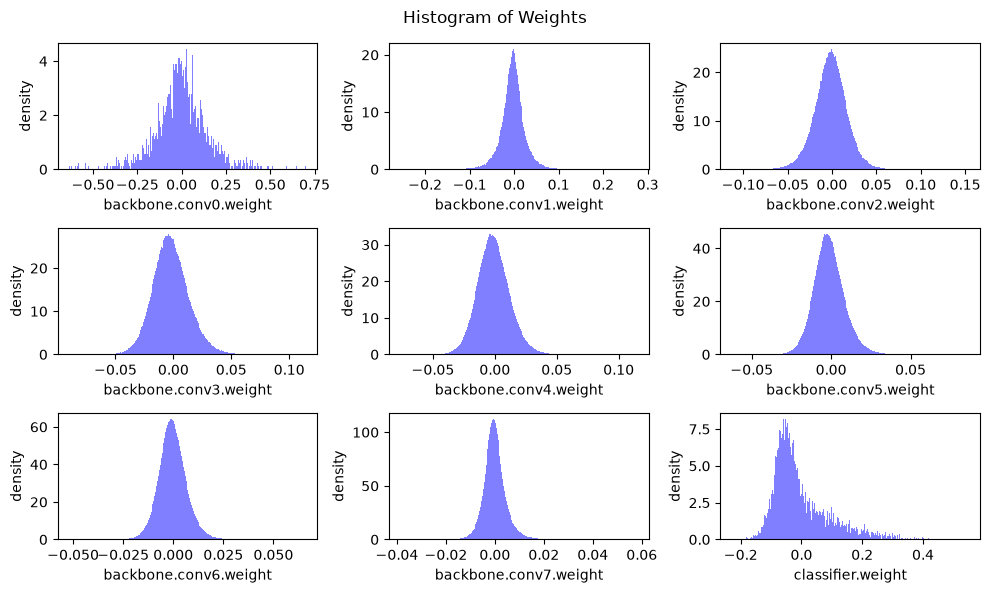

In [31]:
# 8
def plot_weight_distribution(model, bins=256, count_nonzero_only=False):
    """가중치 분포를 시각화하는 함수

    Args:
        model: 분석할 모델
        bins: 히스토그램의 구간 수 (기본값: 256)
        count_nonzero_only: 0이 아닌 가중치만 표시할지 여부 (기본값: False)
    """
    # 3x3 서브플롯 생성
    fig, axes = plt.subplots(3, 3, figsize=(10, 6))
    axes = axes.ravel()

    plot_index = 0
    for name, param in model.named_parameters():
        # 2차원 이상의 파라미터만 처리 (Conv2d, Linear 레이어의 가중치)
        if param.dim() > 1:
            ax = axes[plot_index]

            # CPU로 데이터 이동 및 1차원으로 변환
            param_data = param.detach().view(-1).cpu()

            if count_nonzero_only:
                # 0이 아닌 값만 선택
                param_data = param_data[param_data != 0]

            # 히스토그램 그리기
            ax.hist(param_data, bins=bins, density=True,
                   color='blue', alpha=0.5)

            # 축 레이블 설정
            ax.set_xlabel(name)
            ax.set_ylabel('density')
            plot_index += 1
    fig.suptitle('Histogram of Weights')
    fig.tight_layout()
    fig.subplots_adjust(top=0.925)
    plt.show()

plot_weight_distribution(model)

### 📘 셀 8 해설
**한 줄 요약:** 9개 층의 가중치 값이 **어떤 범위에 얼마나 몰려 있는지** 히스토그램으로 그립니다.

**코드 뜯어보기**
- `fig, axes = plt.subplots(3, 3, figsize=(10, 6))` : 3행 3열, 총 9칸짜리 그림판을 만듭니다(층이 9개라서).
- `axes = axes.ravel()` : 3×3 표 형태의 칸들을 **한 줄(0~8번)**로 펴서 `axes[0]`, `axes[1]`처럼 쓰기 쉽게 만듭니다.
- `model.named_parameters()` : `(이름, 가중치)` 쌍을 하나씩 꺼내 줍니다. 예) `('backbone.conv0.weight', 텐서)`
- `if param.dim() > 1` : **2차원 이상**인 것만 고릅니다 → Conv(4차원)와 Linear(2차원)의 weight만 선택되고, BatchNorm 같은 1차원 파라미터는 제외됩니다.
- `param.detach().view(-1).cpu()`
  - `detach()` : 기울기 추적에서 떼어 낸 "값만" 가져옴
  - `view(-1)` : 모양을 **1줄로** 펼침 (`-1`은 "길이는 알아서 계산해 줘")
  - `cpu()` : 그래프는 CPU에서 그리므로 GPU → CPU로 이동
- `param_data[param_data != 0]` : **조건에 맞는 값만 골라내기**(불리언 인덱싱). 0이 아닌 값만 남깁니다.
- `ax.hist(..., bins=256, density=True)` : 값을 256개 구간으로 나눠 막대그래프로. `density=True`는 높이를 개수가 아닌 **비율**로 표시합니다.
- `plot_index += 1` : 다음 칸으로 이동 (`plot_index = plot_index + 1`과 같음)

**그래프 해석:** 대부분의 층에서 가중치가 **0 근처에 몰린 종 모양**으로 나타납니다. 즉 "0에 가까운(=영향이 작은) 가중치가 아주 많다" → 이들을 지워도 괜찮지 않을까? 가 프루닝의 출발점입니다.

이로써 실습을 위한 기본적인 준비는 모두 마무리 되었습니다.

## Reconstruction Error 계산 함수 정의

실습에 들어가기 앞서 **reconstruction error**를 계산하는 함수를 정의하겠습니다. Reconstruction error는 프루닝 전후 모델 출력의 차이를 측정하여 프루닝이 모델의 성능에 미치는 영향을 정량적으로 평가하는 지표입니다.

Input feature map $X$에 대해 원본 weight $W$와 pruning된 weight $\widehat{W}$ 사이의 reconstruction error는 다음 수식으로 계산됩니다:

${\left\Vert WX - \widehat{W}X \right\Vert}^2_2$

이 값이 작을수록 프루닝 후에도 원래 모델의 출력과 유사한 결과를 유지한다는 것을 의미합니다.

In [32]:
# 9
def get_reconstuction_error(tensor1: torch.Tensor, tensor2: torch.Tensor) -> float:
    return torch.sum((tensor1 - tensor2) ** 2).item()

### 📘 셀 9 해설
**한 줄 요약:** 두 텐서가 **얼마나 다른지를 숫자 하나로** 나타내는 함수입니다. (차이를 제곱해서 전부 더한 값)

- `tensor1 - tensor2` : 같은 위치끼리 뺌
- `** 2` : 제곱 → 음수 차이도 양수가 되고, 큰 차이일수록 더 크게 반영됨
- `torch.sum(...)` : 전부 더함
- `.item()` : 결과 텐서를 파이썬 숫자로 변환

위 마크다운의 수식 $\left\Vert WX - \widehat{W}X \right\Vert^2_2$을 그대로 코드로 옮긴 것으로, 여기서는 `tensor1` = 원본 층의 출력, `tensor2` = 프루닝된 층의 출력이 들어갑니다. **값이 작을수록 프루닝 후에도 출력이 원본과 비슷하다**는 뜻입니다. (셀 17에서 사용)

> 함수 이름의 `reconstuction`은 `reconstruction`의 오타이지만, 뒤에서도 같은 이름으로 부르므로 문제없이 동작합니다.

# 1.1. Pruning Granularity/Pattern

이 섹션에서는 Pruning을 수행할 때 다양한 granularity(세분성)를 적용하는 방법을 배웁니다. 각 granularity는 모델의 정확도(accuracy)와 하드웨어 효율성(hardware efficiency)에 영향을 미치므로, 적절한 선택이 중요합니다.


## Pruning Granularity 소개
Pruning granularity는 Pruning이 적용되는 범위를 정의합니다. 다음과 같은 다양한 단위로 Pruning을 적용할 수 있습니다:
- **Fine-grained Pruning**: 가장 작은 단위인 개별 가중치를 대상으로 합니다.
- **Vector-level Pruning**: 가중치 벡터 단위로 Pruning을 수행합니다.
- **Kernel-level Pruning**: 컨볼루션 커널 전체를 대상으로 합니다.
- **Channel-level Pruning**: 전체 채널을 Pruning 대상으로 합니다.

각 단위는 Pruning이 모델의 구조와 성능에 미치는 영향을 다르게 하므로, 실험을 통해 각 경우의 효과를 비교해 볼 필요가 있습니다.

## Pruning Pattern의 시각화
다음 그림은 다양한 Pruning pattern을 보여줍니다. 이를 통해 각 Pruning 기법의 특징을 시각적으로 이해할 수 있습니다.

![Pruning Granularity](https://github.com/SKKU-ESLAB/pytorch-models/blob/main/pruning_granularity.png?raw=true)

본 실습에서는 가중치의 크기(Magnitude)를 기준으로 하는 중요도 점수를 사용합니다. Sparsity를 0.5로 설정하여 `model.backbone.conv1.weight`의 50%에 해당하는 가중치를 제거(Pruning)합니다. 이는 가중치의 절반을 0으로 만들어 모델을 희소화하는 과정입니다.

In [33]:
# 10
prune_sparsity = 0.5
weight = model.backbone.conv1.weight
print(weight.shape)

torch.Size([128, 64, 3, 3])


### 📘 셀 10 해설
**한 줄 요약:** 실험 대상을 정합니다 — **conv1 층의 가중치**를 **50%** 프루닝해 보겠다는 설정입니다.

- `prune_sparsity = 0.5` : **sparsity(희소도)** = 0으로 만들 가중치의 비율. 0.5면 절반을 지웁니다.
- `weight = model.backbone.conv1.weight` : 점(`.`)으로 안쪽을 따라 들어갑니다. 모델 → backbone → conv1 → weight
- `weight.shape` : 텐서의 모양

**출력 해석:** `torch.Size([128, 64, 3, 3])`

| 차원 | 값 | 의미 |
|---|---|---|
| 0 | 128 | 출력 채널 수 (필터 개수) |
| 1 | 64 | 입력 채널 수 |
| 2 | 3 | 커널 높이 |
| 3 | 3 | 커널 너비 |

즉 "3×3짜리 작은 격자(커널)"가 128×64 = 8,192개 있고, 숫자는 총 73,728개입니다. 뒤의 4가지 프루닝 방식은 **이 4개 차원 중 어느 단위로 묶어서 지우느냐**의 차이입니다.

## 가중치 분포 시각화

Pruning을 수행하기 전에 가중치의 분포를 시각화하여 중요한 가중치들을 파악하고 Pruning이 미치는 영향을 분석합니다. 아래 함수를 통해 가중치의 분포를 시각적으로 확인할 수 있습니다:

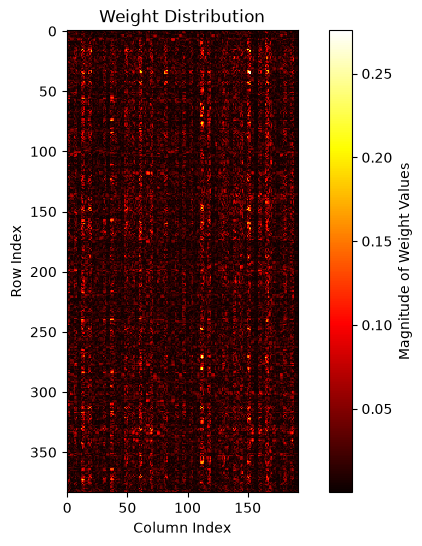

In [34]:
# 11
def draw_weight_distribution(weight_tensor, title="Weight Distribution"):
    weights = weight_tensor.detach().cpu().numpy()

    # 4D 텐서인 경우 2D로 재구성
    if len(weights.shape) == 4:
        co, ci, kh, kw = weights.shape
        weights = weights.transpose(0, 2, 1, 3).reshape(co * kh, ci * kw)

    plt.figure(figsize=(8, 6))
    plt.imshow(weights, cmap='hot', interpolation='nearest')
    plt.colorbar(label='Magnitude of Weight Values')
    plt.title(title)
    plt.xlabel("Column Index")
    plt.ylabel("Row Index")
    plt.show()

# 가중치의 절댓값 분포 시각화
draw_weight_distribution(weight.abs())

### 📘 셀 11 해설
**한 줄 요약:** 4차원 가중치를 **한 장의 2D 그림(히트맵)**으로 펼쳐서 보여 주는 함수입니다.

**코드 뜯어보기**
- `weight_tensor.detach().cpu().numpy()` : 텐서를 그림 그리기용 numpy 배열로 변환
- `co, ci, kh, kw = weights.shape` : 모양 (128, 64, 3, 3)을 변수 4개에 **한 번에 나눠 담기**(언패킹)
- `weights.transpose(0, 2, 1, 3)` : 차원 순서를 (출력채널, **커널높이, 입력채널**, 커널너비)로 바꿈
- `.reshape(co * kh, ci * kw)` : (128×3, 64×3) = **384행 × 192열**의 2D 표로 만듦
  - 이렇게 하면 3×3 커널들이 **바둑판 타일처럼** 나란히 놓입니다. 세로 방향 = 출력 채널, 가로 방향 = 입력 채널
- `plt.imshow(weights, cmap='hot')` : 숫자를 색으로 표시. `'hot'` 색상표는 **값이 클수록 밝은 색**(검정 → 빨강 → 노랑 → 흰색)
- `plt.colorbar(...)` : 색과 값의 대응표 표시

마지막 줄 `draw_weight_distribution(weight.abs())`에서 `abs()`는 **절댓값**입니다. 이 실습에서는 "절댓값이 클수록 중요한 가중치"로 보기 때문에(Magnitude 기준), 그림에서 **밝은 점 = 중요한 가중치, 어두운 점 = 지워질 후보**입니다.

## [실습 1] Fine-grained Pruning 구현

Fine-grained Pruning은 신경망의 가중치를 개별적으로 제거하는 기법입니다. 각 가중치의 크기(Magnitude)를 기준으로 중요도를 평가하고, 지정된 희소도(sparsity)에 따라 중요도가 낮은 가중치들을 0으로 만듭니다. 이를 통해 모델의 크기를 줄이고 연산량을 감소시킬 수 있습니다.

아래 빈칸을 채워 `prune_weight_fine_grained` 함수를 완성하세요.

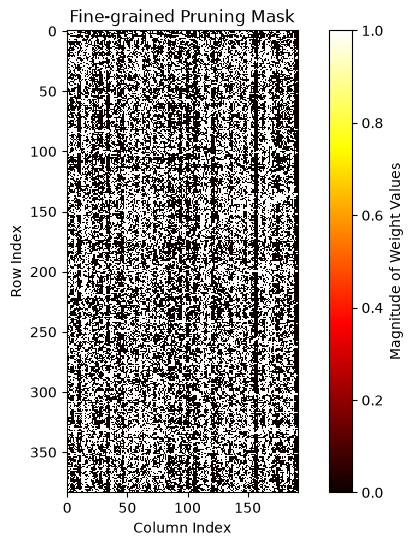

In [35]:
# 12
def prune_weight_fine_grained(weight: torch.Tensor, sparsity: float) -> None:
    """가중치 텐서에 대해 fine-grained pruning을 수행하는 함수

    Args:
        weight: pruning할 가중치 텐서
        sparsity: pruning할 비율 (0~1 사이 값)

    Returns:
        pruning mask 텐서
    """
    # sparsity 값을 0~1 사이로 제한
    sparsity = min(1.0, max(0.0, sparsity))

    # 특수한 경우 처리
    if sparsity == 1.0:  # 모든 가중치를 제거
        weight.zero_()
        return torch.zeros_like(weight)
    elif sparsity == 0.0:  # 모든 가중치를 유지
        return torch.ones_like(weight)

    ##################### YOUR CODE STARTS HERE #####################
    # 제거할 원소 개수를 계산하세요.
    # hint: round() 함수를 사용하세요.
    num_pruned_elements = round(weight.numel() * sparsity)

    # 가중치의 중요도를 절댓값으로 importance 계산
    # hint: torch.abs() 함수를 사용하세요.
    importance = torch.abs(weight)

    # pruning trheshold를 계산하세요.
    # hint: torch.kthvalue() 함수를 사용하세요.
    threshold = torch.kthvalue(importance.flatten(), num_pruned_elements)[0]

    # threshold보다 큰 값들은 유지(1), 작은 값들은 제거(0)하는 마스크 생성
    # hint: 부등호를 사용하세요.
    mask = importance > threshold
    ##################### YOUR CODE ENDS HERE #######################

    # 마스크를 적용하여 pruning 수행
    weight.mul_(mask)

    return mask

# 마스크 생성 및 시각화
mask_fine_grained = prune_weight_fine_grained(weight.clone(), prune_sparsity)
draw_weight_distribution(mask_fine_grained, title="Fine-grained Pruning Mask")

### 📘 셀 12 해설
**한 줄 요약:** [실습 1 정답] 가중치를 **낱개 단위**로 보고, 절댓값이 작은 것부터 `sparsity` 비율만큼 0으로 만드는 함수입니다.

**앞부분 (미리 주어진 코드)**
- `sparsity = min(1.0, max(0.0, sparsity))` : 값을 0~1 사이로 **강제로 맞춤**. 예) 1.3 → 1.0, -0.2 → 0.0
- `sparsity == 1.0`이면 전부 0으로(`weight.zero_()`), `0.0`이면 아무것도 지우지 않고 바로 `return`
- `torch.zeros_like(weight)` / `torch.ones_like(weight)` : `weight`와 **같은 모양**으로 0 / 1만 채운 텐서

**정답 4줄 (핵심)**

| 코드 | 의미 | conv1 예시 |
|---|---|---|
| `num_pruned_elements = round(weight.numel() * sparsity)` | 지울 개수 = 전체 개수 × 비율 (반올림) | 73,728 × 0.5 = 36,864개 |
| `importance = torch.abs(weight)` | 중요도 = 절댓값 (부호는 무시, 크기만 봄) | |
| `threshold = torch.kthvalue(importance.flatten(), num_pruned_elements)[0]` | 중요도를 한 줄로 펴고, **k번째로 작은 값**을 찾음 = 커트라인 | 36,864번째로 작은 값 |
| `mask = importance > threshold` | 커트라인보다 크면 `True`(유지), 아니면 `False`(제거) | |

- `torch.kthvalue`는 `(값, 위치)` 두 개를 돌려주기 때문에 `[0]`으로 **값만** 꺼냅니다.
- `flatten()`은 다차원 텐서를 1줄로 펴는 함수입니다(`view(-1)`과 비슷).

**마무리**
- `weight.mul_(mask)` : 가중치에 마스크를 곱합니다. `True`=1, `False`=0으로 계산되므로 **지울 자리만 0**이 됩니다.
- PyTorch에서 이름 끝에 **밑줄 `_`**이 붙은 함수(`mul_`, `zero_`)는 새 텐서를 만들지 않고 **원본을 직접 수정**합니다.

**아래 실행 부분**
- `prune_weight_fine_grained(weight.clone(), prune_sparsity)` : `clone()`으로 **복사본**을 넘겼기 때문에 실제 모델의 가중치는 바뀌지 않고, 마스크만 얻습니다.

**그림 해석:** 밝은 점(1=유지)과 어두운 점(0=제거)이 **규칙 없이 흩어져** 있습니다. 가장 자유롭게 지우기 때문에 정확도에는 유리하지만, 0이 여기저기 흩어져 있어 하드웨어에서 속도 이득을 얻기는 어렵습니다.

> 함수 정의의 `-> None`은 "아무것도 돌려주지 않는다"는 타입 힌트인데, 실제로는 `mask`를 돌려줍니다. 힌트가 정확하지 않을 뿐 실행에는 지장이 없습니다.

## Vector-level Pruning

Vector-level Pruning은 가중치 벡터 단위로 Pruning을 수행하는 기법입니다. 이 방법은 fine-grained Pruning과 비교했을 때 구조적인 정보를 더 잘 보존할 수 있다는 장점이 있습니다. 각 가중치 벡터의 L1 norm(절대값의 합)을 기준으로 중요도를 평가하고, 중요도가 낮은 벡터들을 제거함으로써 Pruning을 수행합니다. 이러한 방식으로 네트워크의 구조적 특성을 유지하면서 모델을 경량화할 수 있습니다.

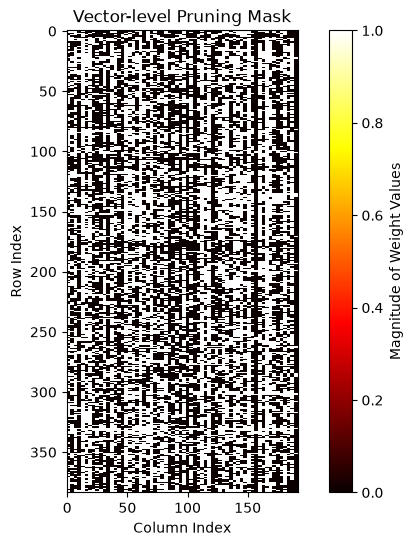

In [36]:
# 13
def prune_weight_vector_level(weight: torch.Tensor, sparsity: float) -> None:
    """벡터 단위로 가중치를 프루닝하는 함수입니다.

    Args:
        weight: 프루닝할 가중치 텐서
        sparsity: 프루닝할 비율 (0~1 사이 값)

    Returns:
        프루닝 마스크 텐서
    """
    # sparsity 값을 0~1 사이로 제한
    sparsity = min(1.0, max(0.0, sparsity))

    # 특수한 경우 처리
    if sparsity == 1.0:  # 모든 가중치를 제거
        weight.zero_()
        return torch.zeros_like(weight)
    elif sparsity == 0.0:  # 모든 가중치를 유지
        return torch.ones_like(weight)

    # 제거할 벡터의 개수 계산
    num_vectors = weight.shape[0] * weight.shape[1] * weight.shape[2]
    num_pruned_vectors = round(num_vectors * sparsity)

    # 각 벡터의 중요도를 절댓값 합으로 계산
    importance = weight.abs().sum(dim=(3,), keepdim=True)

    # pruning trheshold를 계산
    threshold = torch.kthvalue(importance.flatten(), num_pruned_vectors)[0]

    # threshold보다 큰 벡터는 유지(1), 작은 벡터는 제거(0)
    mask = importance > threshold

    # 마스크를 가중치와 동일한 크기로 확장
    mask = mask.expand_as(weight)

    # 마스크를 적용하여 프루닝 수행
    weight.mul_(mask)

    return mask

mask_vector_level = prune_weight_vector_level(weight.clone(), prune_sparsity)
draw_weight_distribution(mask_vector_level, title="Vector-level Pruning Mask")

### 📘 셀 13 해설
**한 줄 요약:** 3×3 커널 안의 **가로 한 줄(숫자 3개)**을 한 묶음(벡터)으로 보고, 묶음 단위로 남기거나 통째로 지웁니다.

셀 12과 구조가 같고, **"묶는 단위"만** 다릅니다.

- `num_vectors = weight.shape[0] * weight.shape[1] * weight.shape[2]` : 벡터 개수 = 128 × 64 × 3 = 24,576개
- `importance = weight.abs().sum(dim=(3,), keepdim=True)`
  - `dim=(3,)` : **3번 차원(커널 너비)** 방향으로 더함 → 가로 한 줄의 절댓값 합 = 그 벡터의 중요도
  - `keepdim=True` : 더한 뒤에도 차원을 없애지 않고 크기 1로 남김 → 모양이 (128, 64, 3, **1**)
  - `(3,)`의 쉼표는 "원소가 1개인 튜플"을 만드는 파이썬 문법입니다.
- `threshold`, `mask` 계산은 셀 12과 동일합니다(이번엔 벡터의 중요도끼리 비교).
- `mask = mask.expand_as(weight)` : (128, 64, 3, 1) 모양의 마스크를 (128, 64, 3, 3)으로 **늘려 복사**합니다. 즉 한 벡터가 탈락이면 그 안의 숫자 3개가 **모두** 0이 됩니다.

**그림 해석:** 낱개 점 대신 **짧은 가로 막대(3칸)** 단위로 켜지고 꺼진 무늬가 보입니다.

## Kernel-level Pruning

Kernel-level Pruning은 컨볼루션 커널을 기준으로 프루닝을 수행하는 방법입니다. 벡터 단위 프루닝보다 더 큰 구조적 단위로 프루닝을 수행하기 때문에 하드웨어 가속과 연산 최적화에 더 효과적입니다. 각 커널의 가중치 절댓값 총합을 중요도로 사용하여 불필요한 커널을 제거합니다.

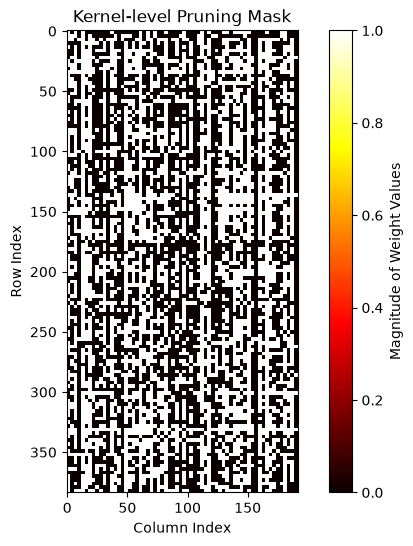

In [37]:
# 14
def prune_weight_kernel_level(weight: torch.Tensor, sparsity: float) -> None:
    """커널 단위로 가중치를 프루닝하는 함수

    Args:
        weight: 프루닝할 가중치 텐서 (out_channels, in_channels, kernel_h, kernel_w)
        sparsity: 프루닝할 비율 (0~1 사이 값)

    Returns:
        프루닝 마스크 텐서
    """
    sparsity = min(1.0, max(0.0, sparsity))
    if sparsity == 1.0:
        weight.zero_()
        return torch.zeros_like(weight)
    elif sparsity == 0.0:
        return torch.ones_like(weight)

    # 프루닝할 커널 수 계산
    num_kernels = weight.shape[0] * weight.shape[1]
    num_pruned_kernels = round(num_kernels * sparsity)

    # 각 커널의 중요도를 절댓값 합으로 계산 (커널 크기에 대해 합산)
    importance = weight.abs().sum(dim=(2, 3), keepdim=True)

    # pruning trheshold를 계산
    threshold = torch.kthvalue(importance.flatten(), num_pruned_kernels)[0]

    # threshold보다 큰 커널은 유지(1), 작은 커널은 제거(0)
    mask = importance > threshold

    # 마스크를 가중치와 동일한 크기로 확장
    mask = mask.expand_as(weight)

    # 마스크를 적용하여 프루닝 수행
    weight.mul_(mask)

    return mask

mask_kernel_level = prune_weight_kernel_level(weight.clone(), prune_sparsity)
draw_weight_distribution(mask_kernel_level, title="Kernel-level Pruning Mask")

### 📘 셀 14 해설
**한 줄 요약:** **3×3 커널 하나(숫자 9개)**를 한 묶음으로 보고, 커널 단위로 남기거나 통째로 지웁니다.

- `num_kernels = weight.shape[0] * weight.shape[1]` : 커널 개수 = 128 × 64 = 8,192개
- `importance = weight.abs().sum(dim=(2, 3), keepdim=True)` : **2번·3번 차원(커널 높이·너비)**에 대해 더함 → 커널 하나의 절댓값 합. 모양은 (128, 64, 1, 1)
- 중요도가 낮은 커널 절반(4,096개)을 골라 `expand_as`로 9칸 전체에 마스크를 적용합니다.

**그림 해석:** **3×3 정사각형 타일** 단위로 켜지고 꺼집니다. 셀 13보다 더 큰 덩어리로 지우기 때문에 무늬가 더 규칙적입니다.

## Channel-level Pruning

Channel-level Pruning은 입력 또는 출력 채널 전체를 Pruning 대상으로 합니다.
채널 단위로 프루닝을 수행하면 해당 채널과 관련된 모든 연산이 제거되므로 모델의 효율성을 향상시킬 수 있습니다.

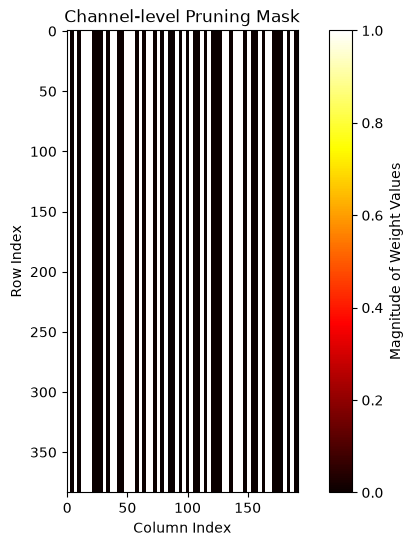

In [38]:
# 15
def prune_weight_channel_level(weight: torch.Tensor, sparsity: float) -> None:
    """채널 단위 프루닝을 수행하는 함수

    Args:
        weight: 프루닝할 가중치 텐서 (out_channels, in_channels, kernel_h, kernel_w)
        sparsity: 프루닝할 비율 (0~1 사이 값)

    Returns:
        프루닝 마스크 텐서
    """
    sparsity = min(1.0, max(0.0, sparsity))
    if sparsity == 1.0:
        weight.zero_()
        return torch.zeros_like(weight)
    elif sparsity == 0.0:
        return torch.ones_like(weight)

    # 프루닝할 채널 수 계산
    num_channels = weight.shape[1]
    num_pruned_channels = round(num_channels * sparsity)

    # 각 채널의 중요도를 절댓값 합으로 계산
    # (출력 채널, 커널 높이, 커널 너비에 대해 합산)
    importance = weight.abs().sum(dim=(0, 2, 3), keepdim=True)

    # pruning threshold를 계산
    threshold = torch.kthvalue(importance.flatten(), num_pruned_channels)[0]

    # threshold보다 큰 채널은 유지(1), 작은 채널은 제거(0)
    mask = importance > threshold

    # 마스크를 가중치와 동일한 크기로 확장
    mask = mask.expand_as(weight)

    # 마스크를 적용하여 프루닝 수행
    weight.mul_(mask)

    return mask

mask_channel_level = prune_weight_channel_level(weight.clone(), prune_sparsity)
draw_weight_distribution(mask_channel_level, title="Channel-level Pruning Mask")

### 📘 셀 15 해설
**한 줄 요약:** **입력 채널 하나 전체**를 한 묶음으로 보고, 채널 단위로 남기거나 통째로 지웁니다.

- `num_channels = weight.shape[1]` : 입력 채널 수 = 64개 → 그중 32개를 제거
- `importance = weight.abs().sum(dim=(0, 2, 3), keepdim=True)` : **1번 차원(입력 채널)만 남기고** 나머지를 전부 더함 → 채널 하나에 속한 128×3×3 = 1,152개 숫자의 절댓값 합. 모양은 (1, 64, 1, 1)
- `expand_as`로 늘리면, 탈락한 채널에 해당하는 **모든 출력 채널·모든 커널 위치**가 0이 됩니다.

**그림 해석:** 그림의 가로 방향이 입력 채널이므로 **세로 줄무늬**(위에서 아래까지 통째로 꺼진 띠)가 나타납니다.

**4가지 방식 한눈에 비교**

| 방식 | 지우는 단위 | 합산 차원 `dim` | 묶음 개수 | 특징 |
|---|---|---|---|---|
| Fine-grained | 숫자 1개 | 없음 | 73,728 | 가장 정밀, 정확도 유리 / 하드웨어 가속 어려움 |
| Vector-level | 가로 한 줄(3개) | `(3,)` | 24,576 | |
| Kernel-level | 커널 1개(9개) | `(2, 3)` | 8,192 | |
| Channel-level | 입력 채널 1개(1,152개) | `(0, 2, 3)` | 64 | 채널 자체를 없앨 수 있어 실제 속도 향상에 가장 유리 / 정확도 손실 큼 |

아래로 갈수록 **덩어리가 커지고(구조적)**, 하드웨어에는 좋지만 중요한 가중치도 함께 지워질 위험이 커집니다.

## 중요도 합 비교

각 프루닝 기법에 따라 제거된 가중치의 중요도 합을 비교합니다. 이를 통해 각 프루닝 방법이 얼마나 중요한 가중치를 제거하는지 파악할 수 있습니다. 중요도가 높은 가중치를 많이 제거할수록 모델의 성능 저하가 클 것으로 예상됩니다.

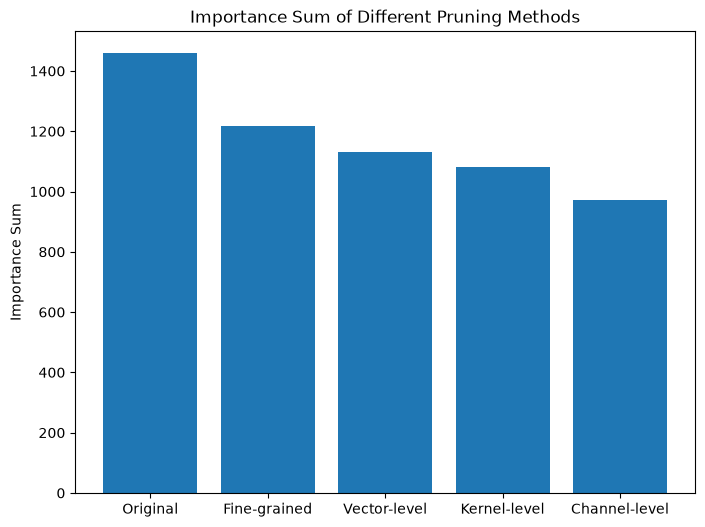

In [39]:
# 16
# 가중치의 중요도를 절댓값으로 계산
importance = weight.abs()

# 각 프루닝 방법별 중요도 합 계산
importance_sum = importance.sum().item()  # 원본
importance_sum_fine_grained = (importance * mask_fine_grained).sum().item()  # 미세 단위
importance_sum_vector_level = (importance * mask_vector_level).sum().item()  # 벡터 단위
importance_sum_kernel_level = (importance * mask_kernel_level).sum().item()  # 커널 단위
importance_sum_channel_level = (importance * mask_channel_level).sum().item()  # 채널 단위

plt.figure(figsize=(8, 6))
plt.bar(['Original', 'Fine-grained', 'Vector-level', 'Kernel-level', 'Channel-level'],
        [importance_sum, importance_sum_fine_grained, importance_sum_vector_level,
         importance_sum_kernel_level, importance_sum_channel_level])
plt.ylabel('Importance Sum')
plt.title('Importance Sum of Different Pruning Methods')
plt.show()

### 📘 셀 16 해설
**한 줄 요약:** 4가지 방식으로 50%씩 지운 뒤, **살아남은 가중치의 중요도(절댓값) 합**을 막대그래프로 비교합니다.

- `importance * mask_fine_grained` : 마스크가 0인 자리는 0이 되므로, **남은 가중치의 중요도만** 남습니다.
- `.sum().item()` : 전부 더해서 파이썬 숫자로 변환
- `plt.bar([이름들], [값들])` : 막대그래프. 첫 번째 리스트가 x축 이름, 두 번째가 막대 높이입니다.

**그래프 해석**
- `Original`은 아무것도 지우지 않았을 때의 합(기준)입니다.
- 네 방식 모두 **똑같이 50%를 지웠는데도** 남은 중요도 합이 다릅니다. 막대가 **높을수록** "덜 중요한 것만 잘 골라 지웠다"는 뜻입니다.
- Fine-grained는 정확히 작은 값만 골라내므로 가장 높고, 묶음이 커질수록(Vector → Kernel → Channel) 묶음 안에 섞여 있던 큰 값도 함께 지워져서 낮아집니다.

> 위 마크다운은 "제거된 가중치의 중요도 합"이라고 설명하지만, 코드가 실제로 계산하는 값은 **남아 있는** 가중치의 합입니다(둘을 더하면 Original).

## Reconstruction Error 비교

각 Pruning 기법을 적용한 후, 모델 출력의 reconstruction error를 비교합니다. 이를 통해 각 Pruning 방법이 모델의 출력에 미치는 영향을 정량적으로 평가할 수 있습니다. Reconstruction error가 클수록 원본 모델의 출력과 더 많이 달라졌음을 의미하며, 이는 해당 Pruning 방법이 모델의 성능에 더 큰 영향을 미칠 수 있음을 나타냅니다.

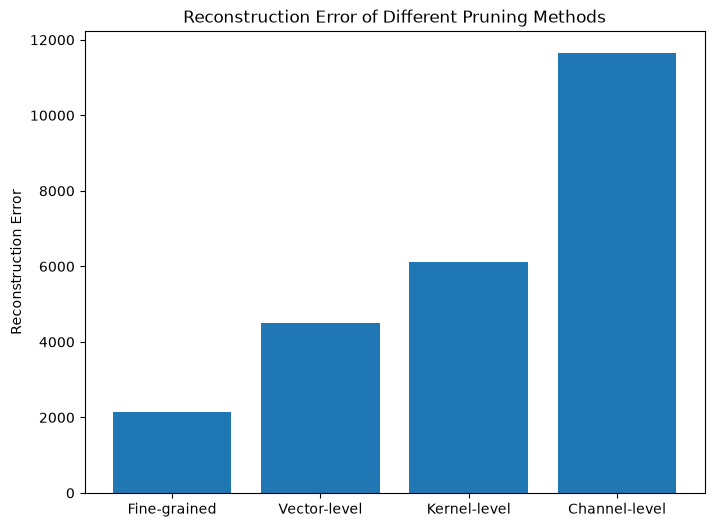

In [40]:
# 17
# 랜덤 입력 샘플 생성
input_sample = torch.randn(1, 64, 32, 32, device=weight.device)

# 원본 컨볼루션 레이어 생성 및 출력 계산
conv_original = nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=False, device=weight.device)
conv_original.weight.data = weight.clone()
output_original = conv_original(input_sample)

# Fine-grained 프루닝 적용 및 재구성 오차 계산
conv_pruned_fine_grained = nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=False, device=weight.device)
conv_pruned_fine_grained.weight.data = weight.clone() * mask_fine_grained
output_pruned_fine_grained = conv_pruned_fine_grained(input_sample)
reconstruction_error_fine_grained = get_reconstuction_error(output_original, output_pruned_fine_grained)

# Vector-level 프루닝 적용 및 재구성 오차 계산
conv_pruned_vector_level = nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=False, device=weight.device)
conv_pruned_vector_level.weight.data = weight.clone() * mask_vector_level
output_pruned_vector_level = conv_pruned_vector_level(input_sample)
reconstruction_error_vector_level = get_reconstuction_error(output_original, output_pruned_vector_level)

# Kernel-level 프루닝 적용 및 재구성 오차 계산
conv_pruned_kernel_level = nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=False, device=weight.device)
conv_pruned_kernel_level.weight.data = weight.clone() * mask_kernel_level
output_pruned_kernel_level = conv_pruned_kernel_level(input_sample)
reconstruction_error_kernel_level = get_reconstuction_error(output_original, output_pruned_kernel_level)

# Channel-level 프루닝 적용 및 재구성 오차 계산
conv_pruned_channel_level = nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=False, device=weight.device)
conv_pruned_channel_level.weight.data = weight.clone() * mask_channel_level
output_pruned_channel_level = conv_pruned_channel_level(input_sample)
reconstruction_error_channel_level = get_reconstuction_error(output_original, output_pruned_channel_level)

# Reconstruction error 시각화
plt.figure(figsize=(8, 6))
plt.bar(['Fine-grained', 'Vector-level', 'Kernel-level', 'Channel-level'],
        [reconstruction_error_fine_grained, reconstruction_error_vector_level,
         reconstruction_error_kernel_level, reconstruction_error_channel_level])
plt.ylabel('Reconstruction Error')
plt.title('Reconstruction Error of Different Pruning Methods')
plt.show()

### 📘 셀 17 해설
**한 줄 요약:** 같은 입력을 원본 층과 프루닝된 층에 각각 넣어 보고, **출력이 얼마나 달라졌는지**(reconstruction error)를 방식별로 비교합니다.

**코드 뜯어보기**
- `torch.randn(1, 64, 32, 32, device=weight.device)` : 정규분포 난수로 채운 **가짜 입력**을 만듭니다. (1장, 64채널, 32×32) — conv1의 입력 모양과 맞춘 것입니다. `device=weight.device`는 가중치와 같은 장치(GPU/CPU)에 만들라는 뜻입니다.
- `nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=False, ...)` : conv1과 **같은 구조**의 새 합성곱 층을 만듭니다.
- `conv_original.weight.data = weight.clone()` : 새 층의 가중치를 conv1 가중치의 복사본으로 **바꿔 끼웁니다.**
- `output_original = conv_original(input_sample)` : 원본 가중치로 계산한 출력
- 프루닝 버전은 `weight.clone() * mask_...`로 **마스크를 곱한 가중치**를 넣는 것만 다릅니다.
- `get_reconstuction_error(output_original, output_pruned_...)` : 셀 9의 함수로 두 출력의 차이를 숫자 하나로 계산합니다.

같은 4줄짜리 블록이 방식 이름만 바뀌어 **4번 반복**되는 구조입니다(반복문으로 줄일 수도 있지만, 읽기 쉽게 풀어 쓴 것입니다).

**그래프 해석:** 막대가 **낮을수록** 원본과 비슷한 출력을 낸다는 뜻입니다. Fine-grained(약 2,200) < Vector(약 4,600) < Kernel(약 6,200) < Channel(약 12,000) 순으로 커지는데, 이는 셀 16의 결과(중요한 가중치를 많이 남길수록 출력이 덜 변한다)와 같은 이야기입니다.

# 1.2. Pruning Ratio

- Layer별 민감도(Sensitivity) 분석
    - 각 레이어의 중요도를 파악하기 위해 특정 레이어만 sparsity를 변화시키면서 정확도 변화를 측정
    - 이를 통해 pruning에 민감한 레이어와 덜 민감한 레이어를 파악

- Non-uniform vs Uniform Pruning 비교
    - Uniform: 모든 레이어에 동일한 pruning ratio 적용
    - Non-uniform: 레이어별 민감도에 따라 global threshold 기반으로 다른 pruning ratio 적용
    - 두 방식 간의 정확도와 모델 크기의 trade-off 비교 분석

## Sensitivity 분석

각 레이어의 민감도를 분석하기 위해 다른 레이어는 고정한 상태에서 특정 레이어의 sparsity를 변화시키며 정확도 변화를 측정합니다. 이를 통해 각 레이어가 pruning에 얼마나 민감한지 파악할 수 있습니다.

In [41]:
# 18
@torch.no_grad()
def sensitivity_scan(model, dataloader, scan_step=0.1, scan_start=0.4, scan_end=1.0, verbose=True):
    """
    각 레이어의 민감도를 분석하기 위한 함수

    Args:
        model: 분석할 모델
        dataloader: 평가에 사용할 데이터로더
        scan_step: sparsity 증가 단위
        scan_start: 시작 sparsity
        scan_end: 종료 sparsity
        verbose: 상세 출력 여부

    Returns:
        sparsities: 테스트한 sparsity 값들
        accuracies: 각 레이어별 sparsity에 따른 정확도
    """
    sparsities = np.arange(start=scan_start, stop=scan_end, step=scan_step)
    accuracies = []

    # 합성곱 레이어의 가중치만 선택
    named_conv_weights = [(name, param) for (name, param) \
                         in model.named_parameters() if param.dim() > 1]

    # 각 레이어별로 민감도 스캔 수행
    for i_layer, (name, param) in enumerate(named_conv_weights):
        param_clone = param.detach().clone()  # 원본 가중치 백업
        accuracy = []

        # 각 sparsity 레벨에서 pruning 수행하고 정확도 측정
        for sparsity in tqdm(sparsities, desc=f'scanning {i_layer}/{len(named_conv_weights)} weight - {name}'):
            prune_weight_fine_grained(param.detach(), sparsity=sparsity)
            acc = evaluate(model, dataloader, verbose=False)

            if verbose:
                print(f'\r    sparsity={sparsity:.2f}: accuracy={acc:.2f}%', end='')
            # restore
            param.copy_(param_clone)
            accuracy.append(acc)
        if verbose:
            print(f'\r    sparsity=[{",".join(["{:.2f}".format(x) for x in sparsities])}]: ' + \
                  f'accuracy=[{", ".join(["{:.2f}%".format(x) for x in accuracy])}]', end='')

        accuracies.append(accuracy)

    return sparsities, accuracies

# 민감도 분석 실행
sparsities, accuracies = sensitivity_scan(
    model, dataloader['test'], scan_step=0.1, scan_start=0.4, scan_end=1.0)

scanning 0/9 weight - backbone.conv0.weight:   0%|          | 0/6 [00:00<?, ?it/s]

    sparsity=[0.40,0.50,0.60,0.70,0.80,0.90]: accuracy=[92.42%, 91.19%, 87.55%, 83.39%, 69.43%, 31.82%]

scanning 1/9 weight - backbone.conv1.weight:   0%|          | 0/6 [00:00<?, ?it/s]

    sparsity=[0.40,0.50,0.60,0.70,0.80,0.90]: accuracy=[92.93%, 92.88%, 92.71%, 92.40%, 91.32%, 84.78%]

scanning 2/9 weight - backbone.conv2.weight:   0%|          | 0/6 [00:00<?, ?it/s]

    sparsity=[0.40,0.50,0.60,0.70,0.80,0.90]: accuracy=[92.94%, 92.64%, 92.46%, 91.77%, 89.85%, 78.56%]

... (8 outputs left out)

scanning 7/9 weight - backbone.conv7.weight:   0%|          | 0/6 [00:00<?, ?it/s]

    sparsity=[0.40,0.50,0.60,0.70,0.80,0.90]: accuracy=[92.93%, 92.91%, 92.89%, 92.81%, 92.63%, 91.34%]

scanning 8/9 weight - classifier.weight:   0%|          | 0/6 [00:00<?, ?it/s]

    sparsity=[0.40,0.50,0.60,0.70,0.80,0.90]: accuracy=[92.91%, 92.83%, 92.82%, 92.97%, 92.67%, 92.52%]

### 📘 셀 18 해설
**한 줄 요약:** **한 번에 한 층씩만** 프루닝해 보면서 "어느 층이 프루닝에 예민한지"를 조사합니다(민감도 분석).

**코드 뜯어보기**
- `np.arange(start=0.4, stop=1.0, step=0.1)` : 0.4부터 0.1 간격으로 **1.0 직전까지** → `[0.4, 0.5, 0.6, 0.7, 0.8, 0.9]`
- `named_conv_weights = [(name, param) for (name, param) in model.named_parameters() if param.dim() > 1]` : **리스트 컴프리헨션**. 조건(`dim() > 1`)에 맞는 9개 층의 `(이름, 가중치)`만 리스트에 담습니다. 줄 끝의 `\`는 "다음 줄에 이어진다"는 표시입니다.
- `for i_layer, (name, param) in enumerate(...)` : `enumerate`는 **번호(0, 1, 2...)와 내용을 함께** 꺼내 줍니다.

**이중 반복문의 흐름** (바깥: 층 9개 / 안쪽: sparsity 6개 → 총 54번 평가)
1. `param_clone = param.detach().clone()` : 원본 가중치를 **백업**
2. `prune_weight_fine_grained(param.detach(), sparsity=sparsity)` : 이번에는 `clone()` 없이 넘기므로 **모델의 실제 가중치가 프루닝**됩니다.
3. `acc = evaluate(model, dataloader, verbose=False)` : 그 상태로 정확도 측정
4. `param.copy_(param_clone)` : 백업으로 **원상 복구** → 다음 실험에 영향을 주지 않음
5. `accuracy.append(acc)` : 결과를 리스트에 추가

- 함수 위의 `@torch.no_grad()` 덕분에 4번처럼 모델 가중치를 직접 덮어쓰는 것이 허용됩니다.
- `print('\r...', end='')` : `\r`은 커서를 **줄 맨 앞으로** 보내 같은 줄을 덮어쓰게 하고, `end=''`는 줄바꿈을 하지 않게 합니다(진행 상황을 한 줄로 갱신).
- `",".join(["{:.2f}".format(x) for x in sparsities])` : 숫자들을 소수 둘째 자리 문자열로 바꾼 뒤 쉼표로 이어 붙입니다.

**출력 해석** (원본 정확도 92.95%)
- **conv0**: 0.6에서 87.55%, 0.9에서 31.81% → **매우 예민**. 첫 층은 가중치 수가 적고 이미지를 처음 받아들이는 층이라 조금만 지워도 타격이 큽니다.
- **conv1, conv6** 등: 0.8에서도 90~91%대 → **둔감**, 많이 지워도 됩니다.
- **conv3, conv4**: 0.8~0.9에서 급락 → 중간 정도로 예민합니다.

각 레이어별 sparsity 변화에 따른 정확도를 시각화하여 sensitivity를 분석합니다.
아래 그래프는 각 레이어의 sparsity 변화에 따른 정확도 변화를 보여주며,
이를 통해 각 레이어의 pruning 민감도를 파악할 수 있습니다.


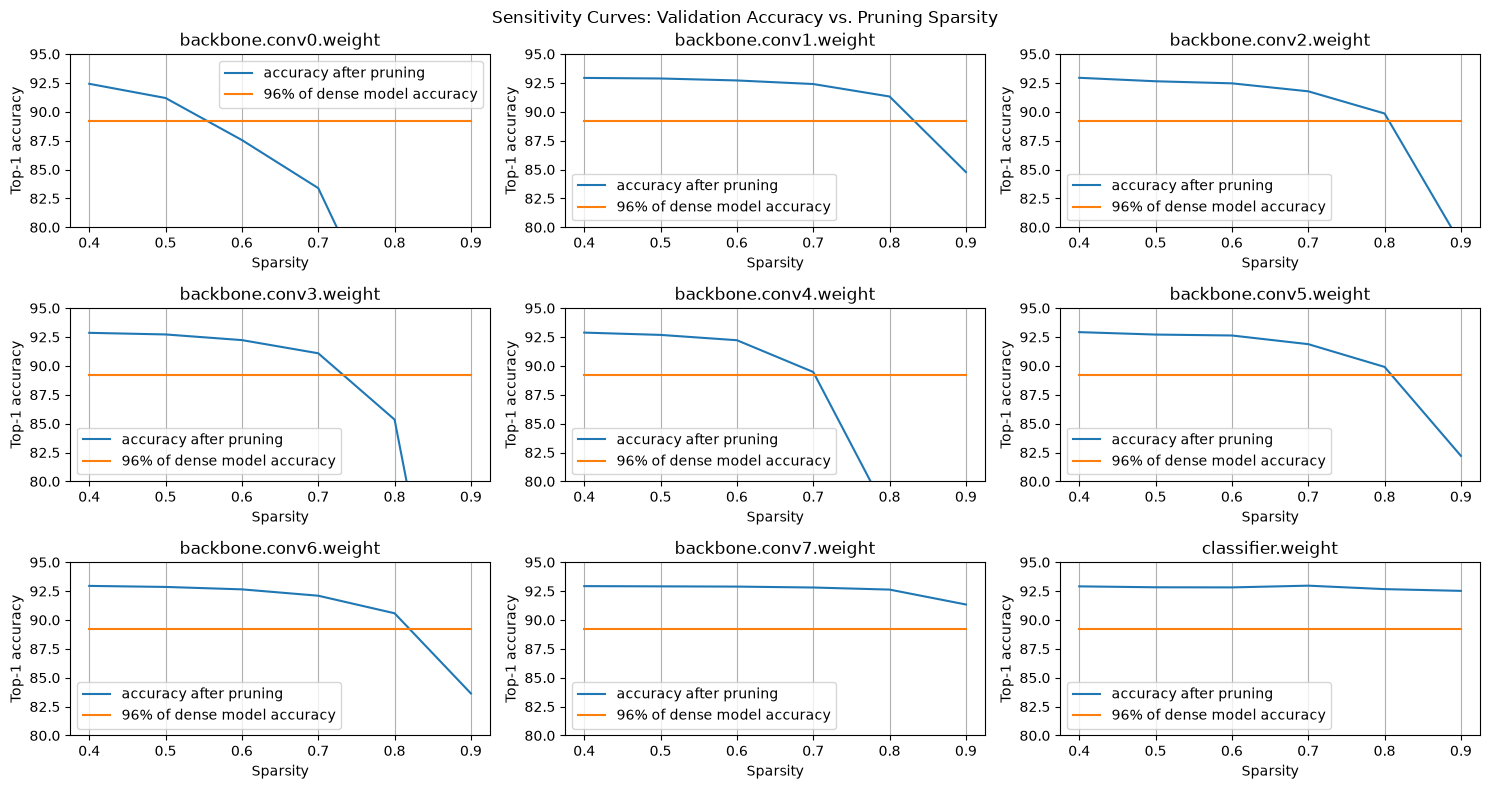

In [42]:
# 19
def plot_sensitivity_scan(sparsities, accuracies, dense_model_accuracy):
    """민감도 스캔 결과를 시각화하는 함수"""
    lower_bound_accuracy = dense_model_accuracy * 0.96  # 기준 정확도의 96%를 하한선으로 설정

    # 서브플롯 생성
    fig, axes = plt.subplots(3, int(math.ceil(len(accuracies) / 3)), figsize=(15, 8))
    axes = axes.ravel()

    # 각 레이어별 민감도 곡선 그리기
    plot_index = 0
    for name, param in model.named_parameters():
        if param.dim() > 1:  # Convolution/Linear 레이어만 선택
            ax = axes[plot_index]

            # 민감도 곡선과 하한선 그리기
            ax.plot(sparsities, accuracies[plot_index], label='accuracy after pruning')
            ax.plot(sparsities, [lower_bound_accuracy] * len(sparsities),
                   label=f'{lower_bound_accuracy/dense_model_accuracy*100:.0f}% of dense model accuracy')

            # 축과 레이블 설정
            ax.set_xticks(np.arange(0.4, 1.0, 0.1))
            ax.set_ylim(80, 95)
            ax.set_title(name)
            ax.set_xlabel('Sparsity')
            ax.set_ylabel('Top-1 accuracy')
            ax.legend()
            ax.grid(axis='x')

            plot_index += 1
    fig.suptitle('Sensitivity Curves: Validation Accuracy vs. Pruning Sparsity')
    fig.tight_layout()
    fig.subplots_adjust(top=0.925)
    plt.show()

plot_sensitivity_scan(sparsities, accuracies, dense_model_accuracy)

### 📘 셀 19 해설
**한 줄 요약:** 셀 18의 결과를 **층마다 한 칸씩** 꺾은선 그래프로 그립니다.

- `lower_bound_accuracy = dense_model_accuracy * 0.96` : 원본 정확도의 96%(약 89.2%)를 **"여기까지는 봐준다"는 기준선**으로 정합니다.
- `plt.subplots(3, int(math.ceil(len(accuracies) / 3)), ...)` : 3행 × (층 개수 ÷ 3을 **올림**한 값)열. 층이 9개이므로 3×3입니다.
- `ax.plot(sparsities, accuracies[plot_index], ...)` : x축 = sparsity, y축 = 정확도인 파란 곡선
- `[lower_bound_accuracy] * len(sparsities)` : 리스트에 `*`를 쓰면 **반복**입니다. 같은 값이 6개 든 리스트 → 수평선(기준선)이 그려집니다.
- `ax.set_ylim(80, 95)` : y축을 80~95%만 보이게 고정 (80% 아래로 떨어진 점은 그림 밖으로 잘려 보이지 않습니다)
- `ax.legend()` 범례, `ax.grid(axis='x')` 세로 격자선

**그래프 읽는 법:** 파란 곡선이 **주황 기준선 아래로 내려가는 지점**이 그 층의 한계입니다. 오른쪽 끝까지 기준선 위에 머무는 층일수록 많이 지워도 되는 층이고, 일찍 떨어지는 층(conv0 등)은 조금만 지워야 합니다. 이 정보를 가지고 다음 실습에서 층별 sparsity를 직접 정합니다.

> 이 함수는 인자로 받지 않은 `model`을 함수 안에서 사용합니다. 파이썬은 함수 안에 없는 변수를 **함수 바깥(전역)**에서 찾기 때문에 동작합니다.

## [실습 2] Sensitivity Analysis를 통한 Pruning 수행

Sensitivity analysis 결과를 바탕으로 각 레이어별 sparsity를 `custom_sparsity_dict`에 입력하세요.

위 그래프의 분석 결과를 토대로 아래와 같이 진행하면 됩니다다:
- 정확도 하락이 적은 레이어: 높은 sparsity 값 설정
- 정확도 하락이 큰 레이어: 낮은 sparsity 값 설정

이러한 레이어별 차등적인 pruning을 통해 모델의 전반적인 성능은 유지하면서 효율적인 압축을 달성하는 것이 목표입니다.

In [43]:
# 20
class FineGrainedPruner:
    """Fine-grained pruning을 수행하는 클래스"""
    def __init__(self, model, sparsity_dict):
        """
        Args:
            model: pruning할 모델
            sparsity_dict: 레이어별 희소성 비율을 담은 딕셔너리
        """
        self.masks = FineGrainedPruner.prune(model, sparsity_dict)

    @torch.no_grad()
    def apply(self, model):
        """마스크를 모델에 적용"""
        for name, param in model.named_parameters():
            if name in self.masks:
                param *= self.masks[name]

    @staticmethod
    @torch.no_grad()
    def prune(model, sparsity_dict):
        """
        모델의 각 레이어에 대해 희소성 비율에 따라 가지치기 수행

        Args:
            model: 가지치기할 모델
            sparsity_dict: 레이어별 희소성 비율을 담은 딕셔너리

        Returns:
            masks: 레이어별 마스크를 담은 딕셔너리
        """
        masks = dict()
        for name, param in model.named_parameters():
            if param.dim() > 1: # we only prune conv and fc weights
                masks[name] = prune_weight_fine_grained(param, sparsity_dict[name])
        return masks

def get_uniform_sparsity_dict(sparsity):
    """
    모든 레이어에 동일한 희소성 비율을 적용하는 딕셔너리 생성

    Args:
        sparsity: 적용할 희소성 비율

    Returns:
        sparsity_dict: 레이어별 동일한 희소성 비율을 담은 딕셔너리
    """
    sparsity_dict = {name: sparsity for name, param in model.named_parameters() if param.dim() > 1}
    return sparsity_dict

### 📘 셀 20 해설
**한 줄 요약:** "층별로 얼마나 지울지 적힌 표(딕셔너리)"를 받아 **모델 전체를 프루닝**하고, 그 **마스크를 기억해 두는 클래스**를 만듭니다.

**클래스(class)란?** 데이터(`self.masks`)와 그 데이터를 다루는 함수(메서드)를 한데 묶은 **설계도**입니다. `pruner = FineGrainedPruner(model, 표)`처럼 호출하면 설계도대로 실제 물건(객체)이 만들어집니다.

| 메서드 | 언제 실행되나 | 하는 일 |
|---|---|---|
| `__init__(self, model, sparsity_dict)` | 객체를 **만들 때** 자동으로 | `prune`을 실행해 모델을 프루닝하고, 받은 마스크들을 `self.masks`에 저장 |
| `apply(self, model)` | `pruner.apply(model)`로 부를 때 | 저장해 둔 마스크를 가중치에 **다시 곱함** (`param *= 마스크`) |
| `prune(model, sparsity_dict)` | `__init__` 안에서 | 층마다 셀 12의 `prune_weight_fine_grained`를 호출하고, `{층이름: 마스크}` 딕셔너리를 돌려줌 |

- `@staticmethod` : `self`가 필요 없는 메서드라는 표시입니다. 그래서 `FineGrainedPruner.prune(...)`처럼 **클래스 이름으로 바로** 부릅니다.
- `@torch.no_grad()` : 기울기 계산 없이 가중치를 직접 수정하기 위한 표시
- `if name in self.masks` : 딕셔너리에 그 이름(키)이 **있는지** 검사
- `masks = dict()` : 빈 딕셔너리 만들기 (`{}`와 같음)

**왜 `apply`가 따로 필요할까?** 프루닝 후 다시 학습(fine-tuning)을 하면 0으로 만든 가중치가 **다시 0이 아닌 값으로 살아납니다.** 그때마다 마스크를 다시 곱해 0으로 되돌리기 위해서입니다(셀 29에서 사용).

**`get_uniform_sparsity_dict(sparsity)`** : **모든 층에 같은 비율**을 적어 넣은 표를 만들어 줍니다. 예) `{'backbone.conv0.weight': 0.5, 'backbone.conv1.weight': 0.5, ...}`

In [44]:
# 21
def get_model_sparsity(model: nn.Module) -> float:
    """
    모델 전체의 sparsity 계산.

    Args:
        model: 스파시티를 계산할 모델

    Returns:
        float: 모델의 전체 스파시티 비율 (0~1 사이 값)
    """
    num_nonzeros, num_elements = 0, 0
    for param in model.parameters():
        num_nonzeros += param.count_nonzero()
        num_elements += param.numel()
    return 1 - float(num_nonzeros) / num_elements

custom_sparsity_dict = {
##################### YOUR CODE STARTS HERE #####################
    # Key는 수정하지 마시고, 각 layer의 sparsity 값을 조정하세요.
    'backbone.conv0.weight': 0.5,
    'backbone.conv1.weight': 0.8,
    'backbone.conv2.weight': 0.8,
    'backbone.conv3.weight': 0.7,
    'backbone.conv4.weight': 0.7,
    'backbone.conv5.weight': 0.8,
    'backbone.conv6.weight': 0.8,
    'backbone.conv7.weight': 0.9,
    'classifier.weight': 0.9
##################### YOUR CODE ENDS HERE #######################
}

# 프루닝 적용 및 평가
pruner = FineGrainedPruner(model, custom_sparsity_dict)
pruner.apply(model)
custom_pruned_model_accuracy = evaluate(model, dataloader['test'])
custom_sparsity = get_model_sparsity(model)
model.recover_model()

# 결과 출력
print(f"custom_pruned_model has accuracy={custom_pruned_model_accuracy:.2f}%")
print(f"Model sparsity: {custom_sparsity:.3f}")

Eval:   0%|          | 0/20 [00:00<?, ?it/s]

custom_pruned_model has accuracy=66.84%
Model sparsity: 0.806


### 📘 셀 21 해설
**한 줄 요약:** [실습 2 정답] 민감도 그래프를 보고 **층별 sparsity를 직접 정해서** 프루닝한 뒤, 정확도와 전체 sparsity를 확인합니다.

**`get_model_sparsity(model)`** — 모델 전체에서 **0인 가중치의 비율**
- 0이 아닌 개수(`count_nonzero`)와 전체 개수(`numel`)를 모든 파라미터에 대해 누적합니다.
- `1 - (0이 아닌 개수 / 전체 개수)` = 0의 비율. 예) 0.806이면 80.6%가 0
- `num_nonzeros, num_elements = 0, 0` : 변수 2개를 한 줄에서 동시에 0으로 초기화

**`custom_sparsity_dict`** — 키(층 이름)는 그대로 두고 값만 조정합니다.

| 층 | 값 | 이유 (셀 18 결과) |
|---|---|---|
| conv0 | 0.5 | 가장 예민한 층 → 적게 지움 |
| conv3, conv4 | 0.7 | 0.8부터 급락 → 중간 |
| conv1, conv2, conv5, conv6 | 0.8 | 0.8까지 잘 버팀 |
| conv7, classifier | 0.9 | 많이 지워도 되는 층 → 많이 지움 |

**실행 순서**
1. `pruner = FineGrainedPruner(model, custom_sparsity_dict)` : 객체를 만드는 순간 프루닝이 수행됩니다.
2. `pruner.apply(model)` : 마스크를 한 번 더 적용(이미 0이라 결과는 같음, 확인 차원)
3. `evaluate(...)`, `get_model_sparsity(model)` : 정확도와 전체 sparsity 측정
4. `model.recover_model()` : 이 실습용 모델에 준비된 기능으로, 가중치를 **프루닝 전 원본 상태로 되돌립니다.** 다음 실험을 깨끗한 모델로 시작하기 위해서입니다.

**출력 해석:** 전체 sparsity `0.806`(약 80%를 제거)에서 정확도 `66.84%`.
- 층을 **하나씩만** 지웠을 때는 대부분 89% 이상이었지만, **9개 층을 동시에** 지우니 손실이 겹쳐서 훨씬 크게 떨어졌습니다. 민감도 분석은 "층 사이의 상호작용"까지는 알려 주지 않는다는 점을 보여 줍니다.
- 그래도 다음 셀에서 볼 "모든 층 똑같이 80%"(41.11%)보다는 훨씬 높습니다.

Sensitivity analysis를 통한 pruning 결과와 비교하기 위해 모든 레이어에 uniform sparsity를 적용했을 때의 accuracy를 측정합니다.

In [45]:
# 22
# 균일한 sparsity 값들을 생성 (0.4부터 0.9까지 0.1 간격)
uniform_sparsities = np.arange(start=0.4, stop=1.0, step=0.1)
accuracies = []

# 각 sparsity 값에 대해 프루닝 수행 및 정확도 측정
for sparsity in uniform_sparsities:
    # 균일한 sparsity로 프루너 생성 및 적용
    pruner = FineGrainedPruner(model, get_uniform_sparsity_dict(sparsity))
    pruner.apply(model)

    # 테스트셋에서 정확도 평가
    accuracy = evaluate(model, dataloader['test'], verbose=False)
    accuracies.append(accuracy)

    # 모델 복구
    model.recover_model()

    # 결과 출력
    print(f"uniform sparsity={sparsity:.2f}: accuracy={accuracy:.2f}%")

uniform sparsity=0.40: accuracy=92.09%
uniform sparsity=0.50: accuracy=90.65%
uniform sparsity=0.60: accuracy=87.24%
uniform sparsity=0.70: accuracy=75.80%
uniform sparsity=0.80: accuracy=41.11%
uniform sparsity=0.90: accuracy=14.57%


### 📘 셀 22 해설
**한 줄 요약:** 비교 대상으로, **모든 층에 똑같은 비율**(40%~90%)을 적용했을 때의 정확도를 차례로 잽니다.

반복문 한 바퀴의 흐름:
1. `get_uniform_sparsity_dict(sparsity)` : 모든 층에 같은 값을 넣은 표 생성
2. `FineGrainedPruner(...)` → `pruner.apply(model)` : 프루닝
3. `evaluate(..., verbose=False)` : 정확도 측정(진행률 막대 숨김)
4. `accuracies.append(accuracy)` : 결과 저장
5. `model.recover_model()` : 원본으로 복구 후 다음 비율로

> 주의: 여기서 `accuracies = []`로 **새로 만들기 때문에**, 셀 18에서 만든 민감도 결과 `accuracies`는 덮어써집니다. 이 셀 이후에 셀 19을 다시 실행하면 오류가 나거나 엉뚱한 그림이 나옵니다. 주피터에서는 **셀 실행 순서**가 중요합니다.

**출력 해석**

| sparsity | 0.4 | 0.5 | 0.6 | 0.7 | 0.8 | 0.9 |
|---|---|---|---|---|---|---|
| 정확도 | 92.10% | 90.66% | 87.25% | 75.80% | 41.11% | 14.57% |

50%까지는 잘 버티다가 70%부터 급격히 무너집니다. 예민한 층(conv0)까지 똑같이 많이 지우기 때문입니다. 0.9의 14.57%는 10개 중 하나를 찍는 수준(10%)에 가깝습니다.

Layer-wise pruning(uniform sparsity)와 global pruning(sensitivity analysis) 방식의 정확도를 비교하는 그래프입니다.

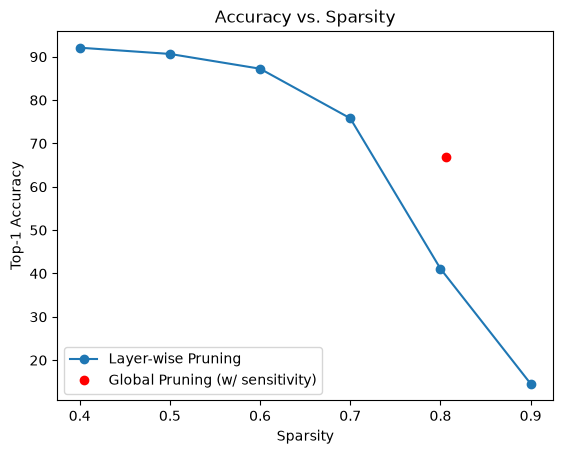

In [46]:
# 23
plt.plot(uniform_sparsities, accuracies, 'o-', label="Layer-wise Pruning")
plt.plot([custom_sparsity], [custom_pruned_model_accuracy], 'ro', label='Global Pruning (w/ sensitivity)')
plt.xlabel('Sparsity')
plt.ylabel('Top-1 Accuracy')
plt.title('Accuracy vs. Sparsity')
plt.legend()
plt.show()

### 📘 셀 23 해설
**한 줄 요약:** "균일 프루닝" 곡선 위에 "민감도 기반 프루닝" 결과를 **빨간 점 하나**로 찍어 비교합니다.

- `plt.plot(x, y, 'o-', label=...)` : `'o-'`는 **동그란 점 + 실선** 스타일
- `plt.plot([custom_sparsity], [custom_pruned_model_accuracy], 'ro', ...)` : `'ro'`는 **빨간(r) 동그라미(o)**. 점 하나만 찍을 때도 x, y를 리스트(`[ ]`)로 감싸서 넘깁니다.
- `plt.legend()` : `label`로 지정한 이름들을 범례로 표시

**그래프 해석:** 빨간 점(sparsity 0.806, 정확도 66.84%)이 파란 선의 같은 x 위치(0.8 → 41.11%)보다 **훨씬 위**에 있습니다. 같은 양을 지우더라도 **층마다 다르게** 지우는 편이 유리하다는 뜻입니다.

> 그래프 범례의 이름이 조금 헷갈릴 수 있습니다. 파란 선 "Layer-wise Pruning" = 모든 층 같은 비율(uniform), 빨간 점 "Global Pruning (w/ sensitivity)" = 민감도를 보고 층별 비율을 손으로 정한 방식입니다.

## [실습 3] Global Magnitude Pruning 구현

이 실습에서는 Global Magnitude Pruning을 구현합니다. Global Magnitude Pruning은 모델의 모든 가중치를 하나의 집합으로 간주하고, 가중치의 절대값을 기준으로 중요도를 평가하여 전체 모델에서 가장 작은 가중치를 제거하는 방식입니다. 이는 각 레이어별로 균일한 비율로 프루닝하는 것이 아니라, 전체 모델에서 가중치의 크기에 따라 프루닝을 수행합니다.

**구현 과정:**
1. 모든 레이어의 가중치를 하나의 벡터로 통합
2. 가중치의 절대값으로 중요도 계산
3. 프루닝 비율에 따른 임계값 설정
4. 임계값 미만의 가중치를 제거하는 마스크 생성 및 적용

이러한 방식으로 모델의 파라미터를 효율적으로 줄이면서도 중요한 정보는 보존할 수 있습니다. 결과적으로 모델 크기와 연산량을 감소시키면서 성능 저하를 최소화하는 것이 목표입니다.

아래 빈칸을 채워 `FineGrainedPrunerV2` 클래스를 완성하세요.

In [47]:
# 24
class FineGrainedPrunerV2:
    def __init__(self, model, sparsity, global_prune=False):
        """
        전역 또는 레이어별 프루닝을 위한 프루너 클래스

        Args:
            model: 프루닝할 모델
            sparsity: 프루닝 비율 (0~1)
            global_prune: 전역 프루닝 여부
        """
        self.masks = FineGrainedPrunerV2.prune(model, sparsity, global_prune)

    @torch.no_grad()
    def apply(self, model):
        """프루닝 마스크를 모델에 적용"""
        for name, param in model.named_parameters():
            if name in self.masks:
                param *= self.masks[name]

    @staticmethod
    @torch.no_grad()
    def prune(model, sparsity, global_prune):
        """
        전역 또는 레이어별 프루닝 수행

        Args:
            model: 프루닝할 모델
            sparsity: 프루닝 비율 (0~1)
            global_prune: 전역 프루닝 여부

        Returns:
            masks: 프루닝 마스크 딕셔너리
        """
        masks = dict()
        if global_prune:
            # 모든 2D 이상의 파라미터를 1차원으로 변환하여 수집
            parameters_to_prune = []
            for name, param in model.named_parameters():
                if param.dim() > 1:  # conv, fc 레이어만 프루닝
                    parameters_to_prune.append(param.view(-1))

            ##################### YOUR CODE STARTS HERE #####################
            # 모든 weight를 하나의 텐서로 결합해주세요..
            # hint: torch.cat()을 사용하세요.
            all_weights = torch.cat(parameters_to_prune)

            # all_weights를 대상으로 global threshold를 구해주세요.
            num_elements = all_weights.numel()
            num_zeros = round(num_elements * sparsity)
            importance = torch.abs(all_weights)
            threshold = torch.kthvalue(importance, num_zeros)[0]
            ##################### YOUR CODE ENDS HERE #######################

            # threshold 기반 마스크 생성
            for name, param in model.named_parameters():
                if param.dim() > 1:
                    mask = torch.abs(param.data) > threshold
                    masks[name] = mask
        else:
            # 레이어별 프루닝 수행
            for name, param in model.named_parameters():
                if param.dim() > 1: # we only prune conv and fc weights
                    masks[name] = prune_weight_fine_grained(param, sparsity)
        return masks

### 📘 셀 24 해설
**한 줄 요약:** [실습 3 정답] 층별 비율을 손으로 정하는 대신, **모든 층의 가중치를 한 줄로 세워 놓고 하나의 커트라인**으로 자르는 프루너입니다.

셀 20의 클래스와 뼈대는 같고, `prune`에 `global_prune` 옵션이 추가되었습니다.

**`global_prune=True`일 때 (전역 프루닝)**
1. `parameters_to_prune.append(param.view(-1))` : 9개 층의 가중치를 각각 1줄로 펴서 리스트에 모읍니다.
2. **(정답)** `all_weights = torch.cat(parameters_to_prune)` : 리스트 안의 텐서들을 **하나의 긴 텐서로 이어 붙임**
3. **(정답)** `num_zeros = round(num_elements * sparsity)` : 전체에서 지울 개수
4. **(정답)** `importance = torch.abs(all_weights)` : 절댓값 = 중요도
5. **(정답)** `threshold = torch.kthvalue(importance, num_zeros)[0]` : 전체에서 `num_zeros`번째로 작은 값 = **모델 전체 공통 커트라인**
6. 다시 층을 돌면서 `mask = torch.abs(param.data) > threshold` : 각 층에 **같은 커트라인**을 적용해 마스크 생성

**`global_prune=False`일 때 (층별 프루닝)** : 셀 20과 같이 층마다 따로 `sparsity` 비율만큼 자릅니다.

**두 방식의 차이 (비유)**
- 층별: "**반마다** 하위 50%를 탈락" → 모든 반에서 같은 비율이 탈락
- 전역: "**전교 석차**로 하위 50%를 탈락" → 성적이 좋은 반은 거의 안 잘리고, 낮은 반은 많이 잘림

결과적으로 층마다 지워지는 비율이 **자동으로** 달라집니다. 값이 작은 가중치가 많은 층은 많이, 큰 가중치가 많은 층은 적게 지워집니다.

> 세부 사항: 전역 모드에서 `prune`은 **마스크만 만들고** 가중치는 아직 건드리지 않습니다. 실제로 0이 되는 것은 `pruner.apply(model)`을 부를 때입니다. (층별 모드는 `prune_weight_fine_grained`가 그 자리에서 바로 0으로 만듭니다.)

In [48]:
# 25
# Golbal Magnitude Pruning 수행
pruner = FineGrainedPrunerV2(model, custom_sparsity, global_prune=True)
pruner.apply(model)

# 프루닝된 모델의 정확도 평가
global_magnitude_pruned_model_accuracy = evaluate(model, dataloader['test'])

# 모델 복구
model.recover_model()

# 결과 출력
print(f"global_magnitude_pruned_model has accuracy={global_magnitude_pruned_model_accuracy:.2f}%")

Eval:   0%|          | 0/20 [00:00<?, ?it/s]

global_magnitude_pruned_model has accuracy=66.27%


### 📘 셀 25 해설
**한 줄 요약:** 방금 만든 전역 프루너로, 실습 2와 **같은 sparsity(0.806)**만큼 지웠을 때의 정확도를 잽니다.

1. `FineGrainedPrunerV2(model, custom_sparsity, global_prune=True)` : 전역 커트라인으로 마스크 생성
2. `pruner.apply(model)` : 마스크를 실제 가중치에 적용 (전역 모드에서는 이 줄이 꼭 필요)
3. `evaluate(...)` : 정확도 측정
4. `model.recover_model()` : 원본으로 복구

**출력 해석:** `66.27%` — 사람이 그래프를 보며 층별로 정한 결과(66.84%)와 **거의 같습니다.** 즉 번거로운 민감도 분석 없이 "절댓값 전교 석차" 규칙 하나만으로 비슷한 성능을 얻었습니다.

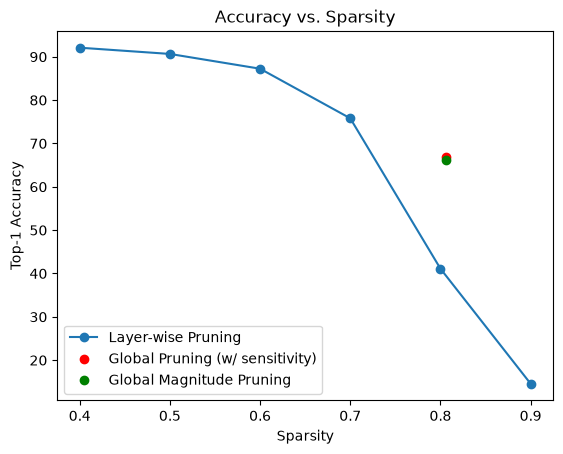

In [49]:
# 26
plt.plot(uniform_sparsities, accuracies, 'o-', label="Layer-wise Pruning")
plt.plot([custom_sparsity], [custom_pruned_model_accuracy], 'ro', label='Global Pruning (w/ sensitivity)')
plt.plot([custom_sparsity], [global_magnitude_pruned_model_accuracy], 'go', label='Global Magnitude Pruning')
plt.xlabel('Sparsity')
plt.ylabel('Top-1 Accuracy')
plt.title('Accuracy vs. Sparsity')
plt.legend()
plt.show()

### 📘 셀 26 해설
**한 줄 요약:** 셀 23의 그래프에 전역 프루닝 결과를 **초록 점**(`'go'` = green + 동그라미)으로 추가합니다.

**그래프 해석:** 빨간 점(민감도 기반, 66.84%)과 초록 점(전역 Magnitude, 66.27%)이 **거의 겹쳐** 보이고, 둘 다 파란 선(균일 프루닝)보다 훨씬 위에 있습니다.

Global magnitude pruning 방식으로 pruning한 모델의 정확도를 다른 pruning 방식과 비교 분석합니다.
Layer-wise pruning, Global pruning (sensitivity 기반), Global magnitude pruning 세 방식의 성능을 비교하여 각 방식의 특징을 비교합니다.

In [50]:
# 27
global_magnitude_pruned_model_accuracies = []
for sparsity in uniform_sparsities:
    pruner = FineGrainedPrunerV2(model, sparsity, global_prune=True)
    pruner.apply(model)
    accuracy = evaluate(model, dataloader['test'], verbose=False)
    global_magnitude_pruned_model_accuracies.append(accuracy)
    model.recover_model()
    print(f"global magnitude sparsity={sparsity:.2f}: accuracy={accuracy:.2f}%")

global magnitude sparsity=0.40: accuracy=92.84%
global magnitude sparsity=0.50: accuracy=92.67%
global magnitude sparsity=0.60: accuracy=92.25%
global magnitude sparsity=0.70: accuracy=89.97%
global magnitude sparsity=0.80: accuracy=69.00%
global magnitude sparsity=0.90: accuracy=18.21%


### 📘 셀 27 해설
**한 줄 요약:** 전역 프루닝도 점 하나가 아니라 **40%~90% 전 구간**에서 측정해, 균일 프루닝과 같은 조건으로 비교할 준비를 합니다.

셀 22과 똑같은 구조의 반복문이고, 프루너만 `FineGrainedPrunerV2(..., global_prune=True)`로 바뀌었습니다. 결과는 새 리스트 `global_magnitude_pruned_model_accuracies`에 따로 저장합니다.

**출력 해석 (균일 프루닝과 비교)**

| sparsity | 0.4 | 0.5 | 0.6 | 0.7 | 0.8 | 0.9 |
|---|---|---|---|---|---|---|
| 균일(셀 22) | 92.10% | 90.66% | 87.25% | 75.80% | 41.11% | 14.57% |
| 전역(이 셀) | 92.83% | 92.67% | 92.25% | 89.97% | 69.00% | 18.21% |

**모든 구간에서 전역 프루닝이 더 높습니다.** 특히 70%에서 약 14%p, 80%에서 약 28%p 차이가 납니다. 다만 90%까지 가면 어떤 방식이든 버티지 못하므로, 그 이상 줄이려면 다음 섹션의 **fine-tuning(재학습)**이 필요합니다.

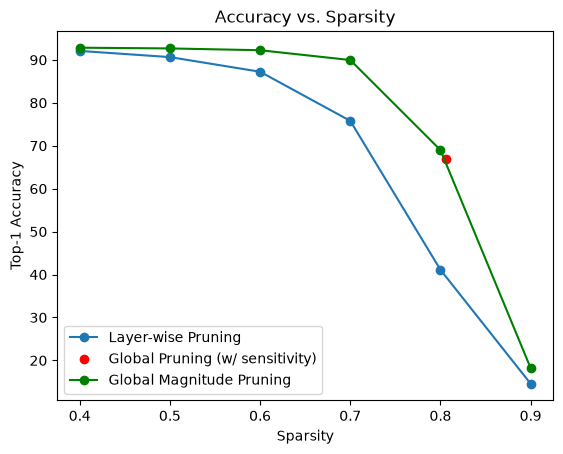

In [51]:
# 28
plt.plot(uniform_sparsities, accuracies, 'o-', label="Layer-wise Pruning")
plt.plot([custom_sparsity], [custom_pruned_model_accuracy], 'ro', label='Global Pruning (w/ sensitivity)')
plt.plot(uniform_sparsities, global_magnitude_pruned_model_accuracies, 'go-', label='Global Magnitude Pruning')
plt.xlabel('Sparsity')
plt.ylabel('Top-1 Accuracy')
plt.title('Accuracy vs. Sparsity')
plt.legend()
plt.show()

### 📘 셀 28 해설
**한 줄 요약:** 세 가지 방식을 한 그래프에 모아 최종 비교합니다.

- 파란 선(`'o-'`): 균일 프루닝 / 초록 선(`'go-'`): 전역 Magnitude 프루닝 / 빨간 점(`'ro'`): 민감도 기반 수동 설정

**그래프 해석:** 초록 선이 파란 선보다 **항상 위**에 있고, 빨간 점은 초록 선 근처에 놓입니다. 정리하면 "어느 층을 얼마나 지울지"를 잘 정하는 것이 중요하고, 전역 Magnitude 방식은 그것을 자동으로 해 주는 간단하고 효과적인 방법입니다.

# 1.3. Pruning Schedule

이 섹션에서는 Pruning 스케줄링을 구현하고, 모델의 Fine-tuning과 함께 Pruning을 진행합니다. Pruning 스케줄링은 모델 학습 중 특정 시점에 가중치를 제거하는 체계적인 접근 방식입니다. 이를 통해 모델의 학습 과정에서 점진적으로 Pruning을 적용하여 성능 저하를 최소화하면서 모델 크기를 효과적으로 줄일 수 있습니다.

**주요 Pruning 스케줄 방식:**
- **One-shot Pruning**: 목표 Pruning 비율을 한 번에 적용한 후, Fine-tuning으로 성능을 회복합니다.
- **Iterative Pruning**: 여러 단계에 걸쳐 점진적으로 Pruning을 수행합니다. 각 단계마다 일정 비율의 가중치를 제거하고 학습을 통해 모델이 새로운 구조에 적응하도록 합니다.

**Iterative Pruning의 스케줄링 방법:**
- **Linear Sparsity Scheduler**: Pruning 비율을 시간에 따라 선형적으로 증가시킵니다.
- **Cubic Sparsity Scheduler**: Pruning 비율을 시간에 따라 세제곱 비율로 증가시켜, 초기에는 급격하게, 후반에는 완만하게 증가시킵니다.

이러한 스케줄러들은 모델이 Pruning에 점진적으로 적응할 수 있게 하여, 최종적으로 원래의 성능을 최대한 유지할 수 있도록 합니다. Pruning 스케줄은 모델의 특성과 요구사항에 맞춰 조정될 수 있으며, 이를 통해 모델의 성능과 효율성의 균형을 맞출 수 있습니다.

## One-shot Pruning

실습 3에서 구현한 `FineGrainedPrunerV2`를 사용하여 One-shot Pruning을 구현합니다.
목표 sparsity를 95%로 설정하고 5 epoch 동안 fine-tuning을 진행합니다.

학습에 사용되는 주요 구성 요소:
- Optimizer: SGD (learning rate=0.01, momentum=0.9, weight_decay=1e-4)
- Scheduler: CosineAnnealingLR
- Loss function: CrossEntropyLoss

In [52]:
# 29
num_finetune_epochs = 5
target_sparsity = 0.95
optimizer = torch.optim.SGD(model.parameters(), lr=0.01, momentum=0.9, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, num_finetune_epochs * len(dataloader['train']))
criterion = nn.CrossEntropyLoss()

pruner = FineGrainedPrunerV2(model, target_sparsity, global_prune=True)

print(f"Finetuning Fine-grained Pruned Sparse Model")
for epoch in range(num_finetune_epochs):
    train(model, dataloader['train'], criterion, optimizer, scheduler,
          callbacks=[lambda: pruner.apply(model)])
    accuracy = evaluate(model, dataloader['test'])
    print(f"   Epoch {epoch+1}/{num_finetune_epochs}: accuracy={accuracy:.2f}%")
model.recover_model()

Finetuning Fine-grained Pruned Sparse Model


Train:   0%|          | 0/98 [00:00<?, ?it/s]

Eval:   0%|          | 0/20 [00:00<?, ?it/s]

   Epoch 1/5: accuracy=89.84%


Train:   0%|          | 0/98 [00:00<?, ?it/s]

Eval:   0%|          | 0/20 [00:00<?, ?it/s]

... (6 outputs left out)

   Epoch 4/5: accuracy=90.68%


Train:   0%|          | 0/98 [00:00<?, ?it/s]

Eval:   0%|          | 0/20 [00:00<?, ?it/s]

   Epoch 5/5: accuracy=90.81%


### 📘 셀 29 해설
**한 줄 요약:** 목표치인 **95%를 한 번에(One-shot)** 지운 다음, 5 에폭 동안 다시 학습(fine-tuning)해서 정확도를 회복시킵니다.

**학습 준비물**

| 코드 | 의미 |
|---|---|
| `num_finetune_epochs = 5` | 학습 데이터 전체를 5바퀴 학습 |
| `target_sparsity = 0.95` | 가중치의 95%를 제거 (5%만 남김) |
| `torch.optim.SGD(model.parameters(), lr=0.01, momentum=0.9, weight_decay=1e-4)` | 가중치를 고치는 도구(**옵티마이저**). `lr`=한 번에 고치는 폭(학습률), `momentum`=이전 방향을 이어가는 관성, `weight_decay`=가중치가 너무 커지지 않게 누르는 힘. `1e-4`는 0.0001 |
| `CosineAnnealingLR(optimizer, 5 * len(dataloader['train']))` | 학습률을 **코사인 곡선 모양으로 서서히 0까지** 줄이는 계획. 두 번째 값은 전체 스텝 수 = 5 에폭 × 98묶음 = 490 |
| `nn.CrossEntropyLoss()` | 분류 문제의 표준 **손실 함수** (예측과 정답의 차이를 계산) |

**프루닝 + 재학습**
- `pruner = FineGrainedPrunerV2(model, target_sparsity, global_prune=True)` : 95%에 해당하는 마스크를 **딱 한 번** 만듭니다.
- `for epoch in range(num_finetune_epochs)` : `range(5)`는 0, 1, 2, 3, 4 → 5번 반복
- `callbacks=[lambda: pruner.apply(model)]`
  - `lambda: ...`는 **이름 없는 한 줄짜리 함수**입니다. "부르면 `pruner.apply(model)`을 실행하는 함수"를 리스트에 담아 넘깁니다.
  - 셀 6의 `train`은 **매 스텝이 끝날 때마다** 이 함수를 실행합니다.
  - 이유: `optimizer.step()`이 가중치를 수정하면 0으로 지운 자리가 다시 살아납니다. 그래서 매번 마스크를 다시 곱해 **지운 자리는 계속 0으로 유지**하고, 남은 5%만 학습되게 합니다.
- 출력의 `{epoch+1}` : 파이썬은 0부터 세므로 사람이 읽기 좋게 1을 더한 것입니다.

**출력 해석:** 89.83% → 90.54% → 90.80% → 90.72% → **90.80%**
- 가중치를 **5%만 남기고도** 원본(92.95%)과 약 2%p 차이입니다. 재학습 없이 90%만 지웠을 때 18.21%였던 것과 비교하면, 남은 가중치가 재학습을 통해 빈자리를 메웠다는 것을 알 수 있습니다.

마지막 `model.recover_model()`로 원본으로 되돌려, 다음 실험(Iterative)도 같은 출발점에서 시작합니다.

## [실습 4] Sparsity Scheduler 구현

이 실습에서는 시간에 따른 Pruning 비율을 조절하는 다음 2가지 Sparsity Scheduler를 구현합니다:
- **Linear sparsity scheduler**: $v^{(t)} = v_f + \left(v_i - v_f\right)\left(1 - \frac{t - t_i}{t_f - t_i}\right)$
    - 시간에 따라 선형적으로 sparsity가 증가
- **Cubic sparsity scheduler**: $v^{(t)} = v_f + \left(v_i - v_f\right)\left(1 - \frac{t - t_i}{t_f - t_i}\right)^3$
    - 시간에 따라 세제곱 비율로 sparsity가 증가

아래 빈 칸을 채워 `get_sparsity_schedule` 함수를 완성하세요.

In [53]:
# 30
def get_sparsity_schedule(num_epochs: int,
                          epoch_start: int,
                          epoch_end: int,
                          sparsity_start: float,
                          sparsity_end: float,
                          exponent: int,
                          ) -> List[float]:
    """
    스파시티 스케줄을 생성하는 함수입니다.

    Args:
        num_epochs: 전체 에폭 수
        epoch_start: 스파시티 스케줄링 시작 에폭
        epoch_end: 스파시티 스케줄링 종료 에폭
        sparsity_start: 시작 스파시티 값
        sparsity_end: 종료 스파시티 값
        exponent: 스케줄링 지수 (1: linear, 3: cubic)

    Returns:
        각 에폭별 스파시티 값 리스트
    """
    sparsity_schedule = []
    ##################### YOUR CODE STARTS HERE #####################
    for epoch in range(num_epochs):
        # 위 수식에 맞게 sparsity를 계산하세요. (단, epoch_start보다 작은 경우 0으로 epochs_end 이후는 sparsity_end로 설정합니다.)
        if epoch < epoch_start:
            sparsity = 0
        elif epoch >= epoch_end:
            sparsity = sparsity_end
        else:
            sparsity = sparsity_end + (sparsity_start - sparsity_end) * (1 - (epoch - epoch_start) / (epoch_end - epoch_start)) ** exponent

        sparsity_schedule.append(sparsity)
    ##################### YOUR CODE ENDS HERE #######################
    return sparsity_schedule

# Linear sparsity schedule
# linear_sparsity_schedule = [0.9, 0.925, 0.95, 0.95, 0.95]
linear_sparsity_schedule = get_sparsity_schedule(num_finetune_epochs, 0, 2, 0.9, target_sparsity, 1)
print("Linear sparsity schedule:", linear_sparsity_schedule)

# Cubic sparsity schedule
# cubic_sparsity_schedule = [0.9, 0.94375, 0.95, 0.95, 0.95]
cubic_sparsity_schedule = get_sparsity_schedule(num_finetune_epochs, 0, 2, 0.9, target_sparsity, 3)
print("Cubic sparsity schedule:", cubic_sparsity_schedule)

Linear sparsity schedule: [0.9, 0.925, 0.95, 0.95, 0.95]
Cubic sparsity schedule: [0.9, 0.94375, 0.95, 0.95, 0.95]


### 📘 셀 30 해설
**한 줄 요약:** [실습 4 정답] "몇 번째 에폭에 몇 %를 지울지"를 미리 계산해 **리스트로 돌려주는** 함수입니다.

**입력값**

| 이름 | 의미 | 아래 호출에서의 값 |
|---|---|---|
| `num_epochs` | 전체 에폭 수 | 5 |
| `epoch_start`, `epoch_end` | sparsity를 올리기 시작/끝내는 에폭 | 0, 2 |
| `sparsity_start`, `sparsity_end` | 시작/최종 sparsity | 0.9, 0.95 |
| `exponent` | 지수. 1이면 Linear, 3이면 Cubic | 1 또는 3 |

**정답 부분** — 에폭마다 3가지 경우로 나눕니다(`if / elif / else`).
- 시작 전(`epoch < epoch_start`) → 0
- 종료 이후(`epoch >= epoch_end`) → 최종값 `sparsity_end`
- 그 사이 → 위 마크다운의 수식을 그대로 옮긴 한 줄
```python
sparsity = sparsity_end + (sparsity_start - sparsity_end) * (1 - (epoch - epoch_start) / (epoch_end - epoch_start)) ** exponent
```
`(epoch - epoch_start) / (epoch_end - epoch_start)`는 **진행률(0~1)**이고, `1 - 진행률`은 **남은 비율**입니다. 남은 비율을 `exponent`번 거듭제곱해서 "최종값까지 남은 거리"에 곱합니다.

**직접 계산해 보기** (에폭 1, 진행률 = 1/2 = 0.5, 남은 비율 = 0.5)
- Linear: 0.95 + (0.9 − 0.95) × 0.5¹ = 0.95 − 0.025 = **0.925**
- Cubic: 0.95 + (0.9 − 0.95) × 0.5³ = 0.95 − 0.00625 = **0.94375**

**출력 해석**
- Linear: `[0.9, 0.925, 0.95, 0.95, 0.95]` — 일정한 간격으로 증가
- Cubic: `[0.9, 0.94375, 0.95, 0.95, 0.95]` — **초반에 빠르게** 올라가고 뒤에서 천천히 마무리

> `-> List[float]`는 "실수(float)들의 리스트를 돌려준다"는 타입 힌트이고, 주석 처리된 줄(`# linear_sparsity_schedule = [...]`)은 기대되는 정답을 미리 적어 둔 메모입니다.

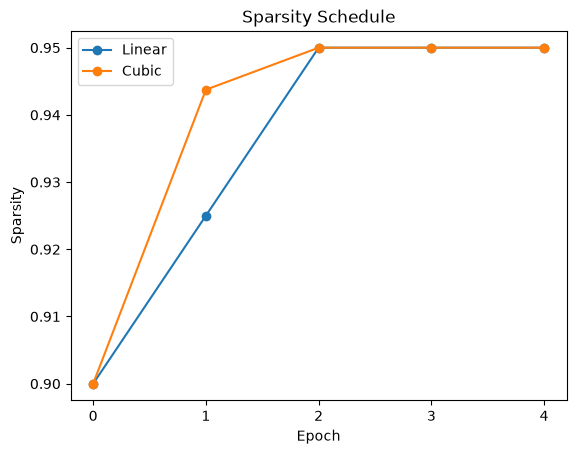

In [54]:
# 31
plt.plot(range(num_finetune_epochs), linear_sparsity_schedule, 'o-', label='Linear')
plt.plot(range(num_finetune_epochs), cubic_sparsity_schedule, 'o-', label='Cubic')
plt.xticks(np.arange(5))
plt.xlabel('Epoch')
plt.ylabel('Sparsity')
plt.title('Sparsity Schedule')
plt.legend()
plt.show()

### 📘 셀 31 해설
**한 줄 요약:** 두 스케줄(Linear, Cubic)을 꺾은선 그래프로 그려 비교합니다.

- `range(num_finetune_epochs)` : x축 값 0, 1, 2, 3, 4 (에폭 번호)
- `plt.xticks(np.arange(5))` : x축 눈금을 0~4의 **정수로만** 표시 (그냥 두면 0.5 같은 눈금이 생길 수 있음)

**그래프 해석:** 두 선 모두 에폭 0에서 0.9로 시작해 에폭 2부터 0.95로 같아집니다. 차이는 **에폭 1** 한 곳으로, Cubic(0.94375)이 Linear(0.925)보다 위에 있습니다. 즉 Cubic은 초반에 많이 지워 놓고 남은 기간을 회복에 씁니다.

## Iterative Pruning

Iterative Pruning은 모델의 가중치를 한 번에 제거하는 대신 여러 단계에 걸쳐 점진적으로 제거하는 방법입니다. 각 단계에서 일정 비율의 가중치를 제거한 후 모델을 재학습시켜 남은 가중치들이 제거된 가중치를 보완할 수 있도록 합니다.

이때 가중치를 제거하는 비율을 조절하는 방법으로 Linear와 Cubic Sparsity Scheduler를 사용할 수 있습니다. Cubic Scheduler는 초기에는 빠르게 가중치를 제거하다가 후반부로 갈수록 천천히 제거하는 방식을 사용합니다. 이는 모델이 후반에 중요한 가중치를 신중하게 제거할 수 있도록 시간을 더 많이 주기 때문에, Linear Scheduler에 비해 일반적으로 더 좋은 성능을 보입니다.

Linear sparsity schedule을 사용하여 iterative pruning을 수행하세요.

In [55]:
# 32
optimizer = torch.optim.SGD(model.parameters(), lr=0.01, momentum=0.9, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, num_finetune_epochs * len(dataloader['train']))
criterion = nn.CrossEntropyLoss()

print(f"Finetuning Fine-grained Pruned Sparse Model with linear sparsity scheduler")
for epoch in range(num_finetune_epochs):
    pruner = FineGrainedPrunerV2(model, linear_sparsity_schedule[epoch], global_prune=True)
    train(model, dataloader['train'], criterion, optimizer, scheduler,
          callbacks=[lambda: pruner.apply(model)])
    accuracy = evaluate(model, dataloader['test'])
    print(f"   Epoch {epoch+1}/{num_finetune_epochs}: accuracy={accuracy:.2f}%")

model.recover_model()

Finetuning Fine-grained Pruned Sparse Model with linear sparsity scheduler


Train:   0%|          | 0/98 [00:00<?, ?it/s]

Eval:   0%|          | 0/20 [00:00<?, ?it/s]

   Epoch 1/5: accuracy=91.73%


Train:   0%|          | 0/98 [00:00<?, ?it/s]

Eval:   0%|          | 0/20 [00:00<?, ?it/s]

... (6 outputs left out)

   Epoch 4/5: accuracy=91.32%


Train:   0%|          | 0/98 [00:00<?, ?it/s]

Eval:   0%|          | 0/20 [00:00<?, ?it/s]

   Epoch 5/5: accuracy=91.22%


### 📘 셀 32 해설
**한 줄 요약:** **Linear 스케줄**에 따라 에폭마다 조금씩 더 지워 가며 학습하는 **Iterative Pruning**입니다.

셀 29(One-shot)과 거의 같고, **달라진 것은 한 줄의 위치**입니다.

```python
# One-shot (셀 29): 반복문 "밖"에서 한 번만, 처음부터 95%
pruner = FineGrainedPrunerV2(model, target_sparsity, global_prune=True)
for epoch in range(num_finetune_epochs):
    train(...)

# Iterative (이 셀): 반복문 "안"에서 에폭마다 새로, 90% → 92.5% → 95%
for epoch in range(num_finetune_epochs):
    pruner = FineGrainedPrunerV2(model, linear_sparsity_schedule[epoch], global_prune=True)
    train(...)
```

- `linear_sparsity_schedule[epoch]` : 리스트에서 **이번 에폭 번호에 해당하는 값**을 꺼냅니다. (에폭 0 → 0.9, 에폭 1 → 0.925, 에폭 2 이후 → 0.95)
- 에폭마다 "조금 더 지우기 → 한 바퀴 학습하며 적응"을 반복합니다. 이미 0이 된 가중치는 절댓값이 가장 작으므로 다음 단계에서도 계속 지워진 상태로 남습니다.
- 옵티마이저와 스케줄러를 **새로 만드는 이유**: 셀 29에서 학습률이 이미 0 근처까지 내려갔기 때문에, 처음 상태(lr=0.01)에서 다시 시작하기 위해서입니다.

**출력 해석:** 91.75% → 91.56% → 90.98% → 91.34% → **91.39%**
- 에폭 3(sparsity가 95%에 처음 도달)에서 잠깐 떨어졌다가 다시 회복합니다.
- 최종 91.39%로 One-shot(90.80%)보다 약 0.6%p 높습니다.

Cubic sparsity schedule을 사용하여 iterative pruning을 수행하세요.

In [56]:
# 33
optimizer = torch.optim.SGD(model.parameters(), lr=0.01, momentum=0.9, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, num_finetune_epochs * len(dataloader['train']))
criterion = nn.CrossEntropyLoss()

print(f"Finetuning Fine-grained Pruned Sparse Model with cubic sparsity scheduler")
for epoch in range(num_finetune_epochs):
    pruner = FineGrainedPrunerV2(model, cubic_sparsity_schedule[epoch], global_prune=True)
    train(model, dataloader['train'], criterion, optimizer, scheduler,
          callbacks=[lambda: pruner.apply(model)])
    accuracy = evaluate(model, dataloader['test'])
    print(f"   Epoch {epoch+1}/{num_finetune_epochs}: accuracy={accuracy:.2f}%")

model.recover_model()

Finetuning Fine-grained Pruned Sparse Model with cubic sparsity scheduler


Train:   0%|          | 0/98 [00:00<?, ?it/s]

Eval:   0%|          | 0/20 [00:00<?, ?it/s]

   Epoch 1/5: accuracy=91.73%


Train:   0%|          | 0/98 [00:00<?, ?it/s]

Eval:   0%|          | 0/20 [00:00<?, ?it/s]

... (6 outputs left out)

   Epoch 4/5: accuracy=91.35%


Train:   0%|          | 0/98 [00:00<?, ?it/s]

Eval:   0%|          | 0/20 [00:00<?, ?it/s]

   Epoch 5/5: accuracy=91.32%


### 📘 셀 33 해설
**한 줄 요약:** 셀 32과 완전히 같은 코드에서 스케줄만 **Cubic**(`cubic_sparsity_schedule`)으로 바꾼 실험입니다. (90% → 94.375% → 95%)

**출력 해석:** 91.69% → 90.97% → 91.23% → 91.48% → **91.42%**

**세 가지 스케줄 최종 비교** (모두 sparsity 95%, 5 에폭)

| 방식 | 최종 정확도 | 원본(92.95%) 대비 |
|---|---|---|
| One-shot (셀 29) | 90.80% | −2.15%p |
| Iterative + Linear (셀 32) | 91.39% | −1.56%p |
| Iterative + Cubic (셀 33) | 91.42% | −1.53%p |

- **한 번에 지우는 것보다 나눠서 지우는 편이** 정확도가 더 잘 유지되었습니다.
- Linear와 Cubic의 차이(0.03%p)는 이 실험에서는 매우 작습니다. 스케줄 구간이 2 에폭으로 짧아 두 스케줄이 에폭 1 한 곳에서만 다르기 때문이며, 이 정도 차이는 실행할 때마다 달라질 수 있는 오차 범위로 보는 것이 안전합니다.

**전체 실습 정리**
1. **무엇을 단위로 지울까 (Granularity)** : 낱개로 지울수록 정확도에 유리하고, 큰 덩어리로 지울수록 하드웨어에 유리합니다.
2. **층마다 얼마나 지울까 (Ratio)** : 모든 층을 똑같이 지우는 것보다, 전역 커트라인이나 민감도를 이용해 층별로 다르게 지우는 편이 좋습니다.
3. **언제 지울까 (Schedule)** : 프루닝 후 재학습을 하면 95%를 지워도 정확도가 대부분 회복되고, 여러 번에 나눠 지우면 조금 더 좋아집니다.